# Telecom Customer Churn — In-Depth Exploratory Data Analysis

**Dataset:** `data/raw/churn.csv` (IBM Telco Customer Churn)  
**Objective:** Understand the structure, quality, distributions, relationships, and business impact of customer attributes on churn, and translate the findings into actionable retention hypotheses.

This notebook covers:

1. Setup and reproducibility
2. Data loading, schema, and data-quality audit
3. Target-variable analysis
4. Feature taxonomy and univariate analysis
5. Categorical and numerical relationships with churn
6. Statistical association and correlation analysis
7. Segment / interaction analysis
8. Revenue-at-risk analysis
9. Consolidated findings and next steps

All figures are saved to `reports/figures/` and tabular summaries to `reports/tables/`.

## 1. Setup and reproducibility

In [1]:
from pathlib import Path
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from scipy import stats

SEED = 42
np.random.seed(SEED)

PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data/raw/churn.csv").exists()),
    Path.cwd(),
)
RAW_PATH = PROJECT_ROOT / "data/raw/churn.csv"
FIG_DIR = PROJECT_ROOT / "reports/figures"
TABLE_DIR = PROJECT_ROOT / "reports/tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.figsize": (10, 6),
    "figure.dpi": 110,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "font.family": "sans-serif",
})

BLUE, RED, GREEN, AMBER, SLATE = "#2563eb", "#dc2626", "#059669", "#d97706", "#475569"
CHURN_PALETTE = {"No": BLUE, "Yes": RED}
CHURN_COLORS = [BLUE, RED]

def save_figure(filename):
    path = FIG_DIR / filename
    plt.savefig(path, dpi=160, bbox_inches="tight", facecolor="white")
    print(f"Saved: {path.relative_to(PROJECT_ROOT)}")

def save_table(df, filename):
    path = TABLE_DIR / filename
    df.to_csv(path, index=False)
    print(f"Saved: {path.relative_to(PROJECT_ROOT)}")

print(f"Project root : {PROJECT_ROOT}")
print(f"Raw data     : {RAW_PATH}")
print(f"Figures      : {FIG_DIR}")
print(f"Tables       : {TABLE_DIR}")

Project root : C:\MLops_Telecom_ChurnPredictionModel
Raw data     : C:\MLops_Telecom_ChurnPredictionModel\data\raw\churn.csv
Figures      : C:\MLops_Telecom_ChurnPredictionModel\reports\figures
Tables       : C:\MLops_Telecom_ChurnPredictionModel\reports\tables


Project root : c:\MLops_Telecom_ChurnPredictionModel
Raw data     : c:\MLops_Telecom_ChurnPredictionModel\data\raw\churn.csv
Figures      : c:\MLops_Telecom_ChurnPredictionModel\reports\figures
Tables       : c:\MLops_Telecom_ChurnPredictionModel\reports\tables


## 2. Data loading and first look

In [2]:
df_raw = pd.read_csv(RAW_PATH)

print(f"Rows    : {df_raw.shape[0]:,}")
print(f"Columns : {df_raw.shape[1]}")
display(df_raw.head(10))

Rows    : 7,043
Columns : 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,...,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.4,No
7,6713-OKOMC,Female,0,No,No,10,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.9,No
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,...,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
9,6388-TABGU,Male,0,No,Yes,62,Yes,No,DSL,Yes,...,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No


In [3]:
schema = df_raw.dtypes.rename("dtype").to_frame()
schema["non_null"] = df_raw.notna().sum()
schema["unique"] = df_raw.nunique()
schema["sample_value"] = df_raw.iloc[0].astype(str)
display(schema)

,dtype,non_null,unique,sample_value
customerID,str,7043,7043,7590-VHVEG
gender,str,7043,2,Female
SeniorCitizen,int64,7043,2,0
Partner,str,7043,2,Yes
Dependents,str,7043,2,No
tenure,int64,7043,73,1
PhoneService,str,7043,2,No
MultipleLines,str,7043,3,No phone service
InternetService,str,7043,3,DSL
OnlineSecurity,str,7043,3,No


### 2.1 Data-quality audit

The audit below checks for missing values, duplicate records, duplicate customer IDs, and non-numeric values in columns that should be numeric.

In [4]:
quality_summary = pd.DataFrame({
    "check": [
        "Total cells",
        "Duplicate full rows",
        "Duplicate customerID values",
        "Missing values (all columns)",
        "Non-numeric TotalCharges values",
        "Customers with tenure = 0",
    ],
    "value": [
        df_raw.size,
        int(df_raw.duplicated().sum()),
        int(df_raw["customerID"].duplicated().sum()),
        int(df_raw.isna().sum().sum()),
        int(pd.to_numeric(df_raw["TotalCharges"], errors="coerce").isna().sum()),
        int((df_raw["tenure"] == 0).sum()),
    ],
})
display(quality_summary)

missing_table = df_raw.isna().sum().rename("missing").to_frame()
missing_table["missing_pct"] = 100 * missing_table["missing"] / len(df_raw)
display(missing_table[missing_table["missing"] > 0] if missing_table["missing"].any() else Markdown("No conventional nulls detected in any column."))

,check,value
0,Total cells,147903
1,Duplicate full rows,0
2,Duplicate customerID values,0
3,Missing values (all columns),0
4,Non-numeric TotalCharges values,11
5,Customers with tenure = 0,11


No conventional nulls detected in any column.

In [5]:
tc_numeric = pd.to_numeric(df_raw["TotalCharges"], errors="coerce")
blank_total_charges = df_raw.loc[tc_numeric.isna(), ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]
print(f"Rows with blank TotalCharges: {len(blank_total_charges)}")
display(blank_total_charges)

Rows with blank TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


**Observation.** `TotalCharges` is stored as text because 11 records contain blank strings. Every one of those records has `tenure = 0`, i.e. they are newly onboarded customers who have not yet been billed. These are not random missing values: they can be converted to `0.0` or excluded from tenure-based charge analyses. There are no duplicate rows or duplicate `customerID` values.

In [6]:
df = df_raw.copy()
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["ChurnFlag"] = (df["Churn"] == "Yes").astype(int)

print("Converted dtypes:")
display(df[["tenure", "MonthlyCharges", "TotalCharges", "Churn", "ChurnFlag"]].dtypes.rename("dtype").to_frame())

Converted dtypes:


,dtype
tenure,int64
MonthlyCharges,float64
TotalCharges,float64
Churn,str
ChurnFlag,int64


## 3. Target variable: churn

In [7]:
target_counts = df["Churn"].value_counts()
target_rate = 100 * df["ChurnFlag"].mean()
n_yes = int(df["ChurnFlag"].sum())
n_total = len(df)
ci = stats.binomtest(n_yes, n_total).proportion_ci(confidence_level=0.95, method="wilson")

target_summary = pd.DataFrame({
    "class": ["No (retained)", "Yes (churned)"],
    "count": [int(target_counts.get("No", 0)), n_yes],
    "share_pct": [100 * target_counts.get("No", 0) / n_total, target_rate],
})
display(target_summary.round(2))

print(f"Overall churn rate: {target_rate:.2f}%  (95% Wilson CI: {100*ci.low:.2f}%–{100*ci.high:.2f}%)")
print(f"Class imbalance   : {(n_total-n_yes)/n_yes:.2f} retained customers per churned customer")

,class,count,share_pct
0,No (retained),5174,73.46
1,Yes (churned),1869,26.54


Overall churn rate: 26.54%  (95% Wilson CI: 25.52%–27.58%)
Class imbalance   : 2.77 retained customers per churned customer


Saved: reports\figures\01_target_distribution.png


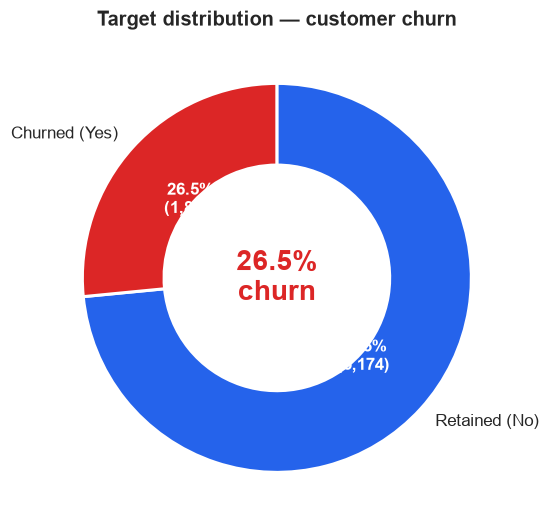

In [8]:
fig, ax = plt.subplots(figsize=(7, 5))
wedges, texts, autotexts = ax.pie(
    [target_counts["No"], target_counts["Yes"]],
    labels=["Retained (No)", "Churned (Yes)"],
    autopct=lambda p: f"{p:.1f}%\n({int(round(p/100*n_total)):,})",
    colors=CHURN_COLORS,
    startangle=90,
    counterclock=False,
    wedgeprops={"width": 0.42, "edgecolor": "white", "linewidth": 2},
    textprops={"fontsize": 11},
)
for t in autotexts:
    t.set_color("white")
    t.set_fontweight("bold")
ax.set_title("Target distribution — customer churn")
ax.text(0, 0, f"{target_rate:.1f}%\nchurn", ha="center", va="center", fontsize=18, fontweight="bold", color=RED)
fig.tight_layout()
save_figure("01_target_distribution.png")
plt.show()

**Interpretation.** The target is moderately imbalanced: 26.54% of customers churned (1,869 of 7,043), with a 95% confidence interval of roughly 25.5%–27.6%. Any predictive model should be evaluated with precision/recall, ROC-AUC, or PR-AUC rather than accuracy alone, and class weighting or resampling should be considered.

## 4. Feature taxonomy and Univariate analysis

In [9]:
ID_COL, TARGET = "customerID", "Churn"
numeric_cols = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen"]
categorical_cols = [c for c in df.columns if c not in [ID_COL, TARGET, "ChurnFlag"] and c not in numeric_cols]

taxonomy = pd.DataFrame({
    "column": df.columns,
    "role": ["identifier" if c == ID_COL else "target" if c == TARGET else "engineered target" if c == "ChurnFlag" else "numeric" if c in numeric_cols else "categorical" for c in df.columns],
    "dtype": df.dtypes.astype(str).values,
    "unique_values": df.nunique().values,
})
display(taxonomy)

print(f"Numeric features      : {numeric_cols}")
print(f"Categorical features  : {len(categorical_cols)}")
print(categorical_cols)

,column,role,dtype,unique_values
0,customerID,identifier,str,7043
1,gender,categorical,str,2
2,SeniorCitizen,numeric,int64,2
3,Partner,categorical,str,2
4,Dependents,categorical,str,2
5,tenure,numeric,int64,73
6,PhoneService,categorical,str,2
7,MultipleLines,categorical,str,3
8,InternetService,categorical,str,3
9,OnlineSecurity,categorical,str,3


Numeric features      : ['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen']
Categorical features  : 15
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [10]:
numeric_summary = df[numeric_cols].describe().T
numeric_summary["skewness"] = df[numeric_cols].skew()
numeric_summary["kurtosis"] = df[numeric_cols].kurt()
numeric_summary["missing"] = df[numeric_cols].isna().sum()
display(numeric_summary.round(2))

,count,mean,std,min,25%,50%,75%,max,skewness,kurtosis,missing
tenure,7043.0,32.37,24.56,0.00,9.00,29.00,55.00,72.00,0.24,-1.39,0
MonthlyCharges,7043.0,64.76,30.09,18.25,35.50,70.35,89.85,118.75,-0.22,-1.26,0
TotalCharges,7032.0,2283.30,2266.77,18.80,401.45,1397.48,3794.74,8684.80,0.96,-0.23,11
SeniorCitizen,7043.0,0.16,0.37,0.00,0.00,0.00,0.00,1.00,1.83,1.36,0


### 4.1 Numeric distributions

Histograms show the shape and spread of each numeric feature, split by churn status. `TotalCharges` excludes the 11 zero-tenure customers because its value is undefined for them.

Saved: reports\figures\02_numeric_distributions.png


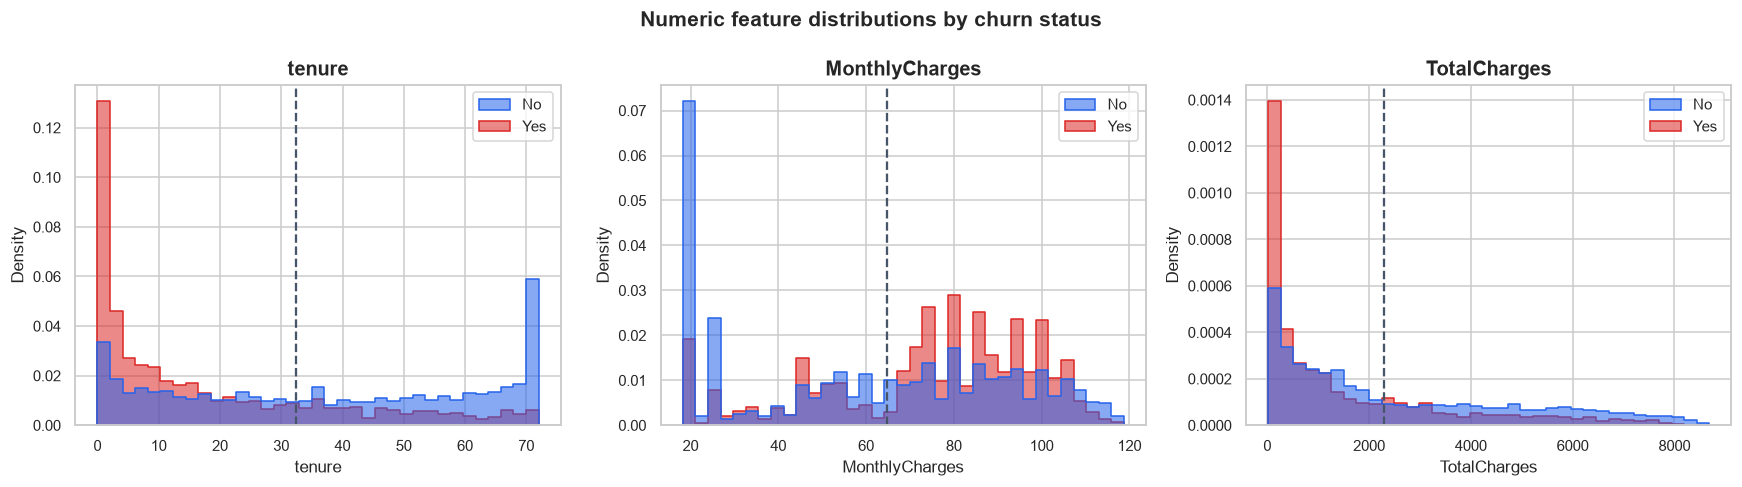

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
plot_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
for ax, col in zip(axes, plot_cols):
    data = df.dropna(subset=[col])
    sns.histplot(data=data, x=col, hue="Churn", bins=35, element="step", stat="density", common_norm=False,
                 palette=CHURN_PALETTE, ax=ax, alpha=0.55)
    ax.axvline(data[col].mean(), color=SLATE, linestyle="--", linewidth=1.5, label=f"mean={data[col].mean():.1f}")
    ax.set_title(col)
    ax.legend_.set_title(None) if ax.legend_ is not None else None
fig.suptitle("Numeric feature distributions by churn status", fontweight="bold", fontsize=14)
fig.tight_layout()
save_figure("02_numeric_distributions.png")
plt.show()

Saved: reports\figures\03_numeric_boxplots_by_churn.png


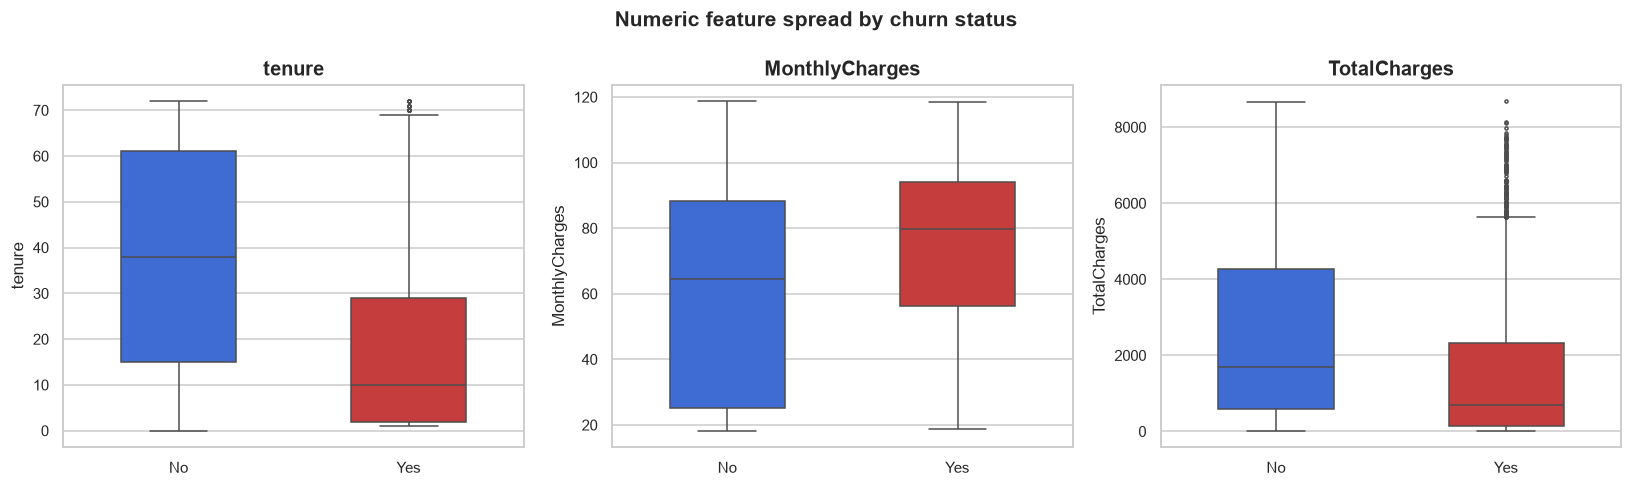

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, col in zip(axes, plot_cols):
    sns.boxplot(data=df.dropna(subset=[col]), x="Churn", y=col, hue="Churn", palette=CHURN_PALETTE,
                legend=False, ax=ax, width=0.5, fliersize=2)
    ax.set_title(col)
    ax.set_xlabel("")
fig.suptitle("Numeric feature spread by churn status", fontweight="bold", fontsize=14)
fig.tight_layout()
save_figure("03_numeric_boxplots_by_churn.png")
plt.show()

**Early signal.** Churned customers have much shorter tenure (median 10 vs 38 months) and pay more per month on average (74.44 vs 61.27). The tenure distributions barely overlap in the first months, suggesting churn is concentrated early in the customer lifecycle.

### 4.2 Categorical distributions

The categorical features are grouped into demographics, services, and account/billing attributes. Stacked bars show both volume and churn composition.

Saved: reports\figures\04_demographics_counts.png


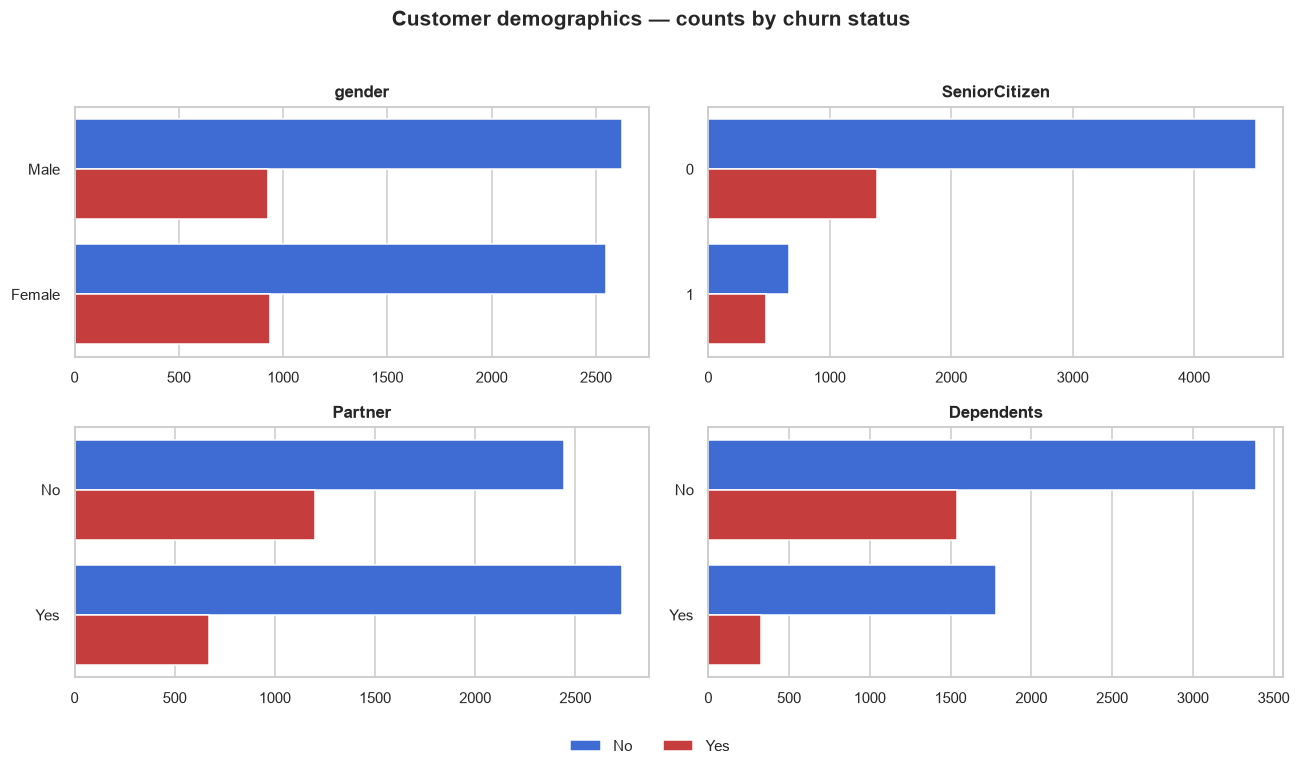

In [13]:
def stacked_count_grid(cols, ncols, figsize, filename, title):
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize)
    axes = np.atleast_1d(axes).ravel()
    for ax, col in zip(axes, cols):
        order = df[col].value_counts().index
        sns.countplot(data=df, y=col, order=order, hue="Churn", palette=CHURN_PALETTE, ax=ax)
        ax.set_title(col, fontsize=11)
        ax.set_xlabel("")
        ax.set_ylabel("")
        if ax.get_legend() is not None:
            ax.get_legend().remove()
    for ax in axes[len(cols):]:
        ax.set_visible(False)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=2, frameon=False)
    fig.suptitle(title, fontweight="bold", fontsize=14)
    fig.tight_layout(rect=[0, 0.05, 1, 0.96])
    save_figure(filename)
    plt.show()

stacked_count_grid(
    ["gender", "SeniorCitizen", "Partner", "Dependents"],
    ncols=2, figsize=(12, 7),
    filename="04_demographics_counts.png",
    title="Customer demographics — counts by churn status",
)

Saved: reports\figures\05_services_counts.png


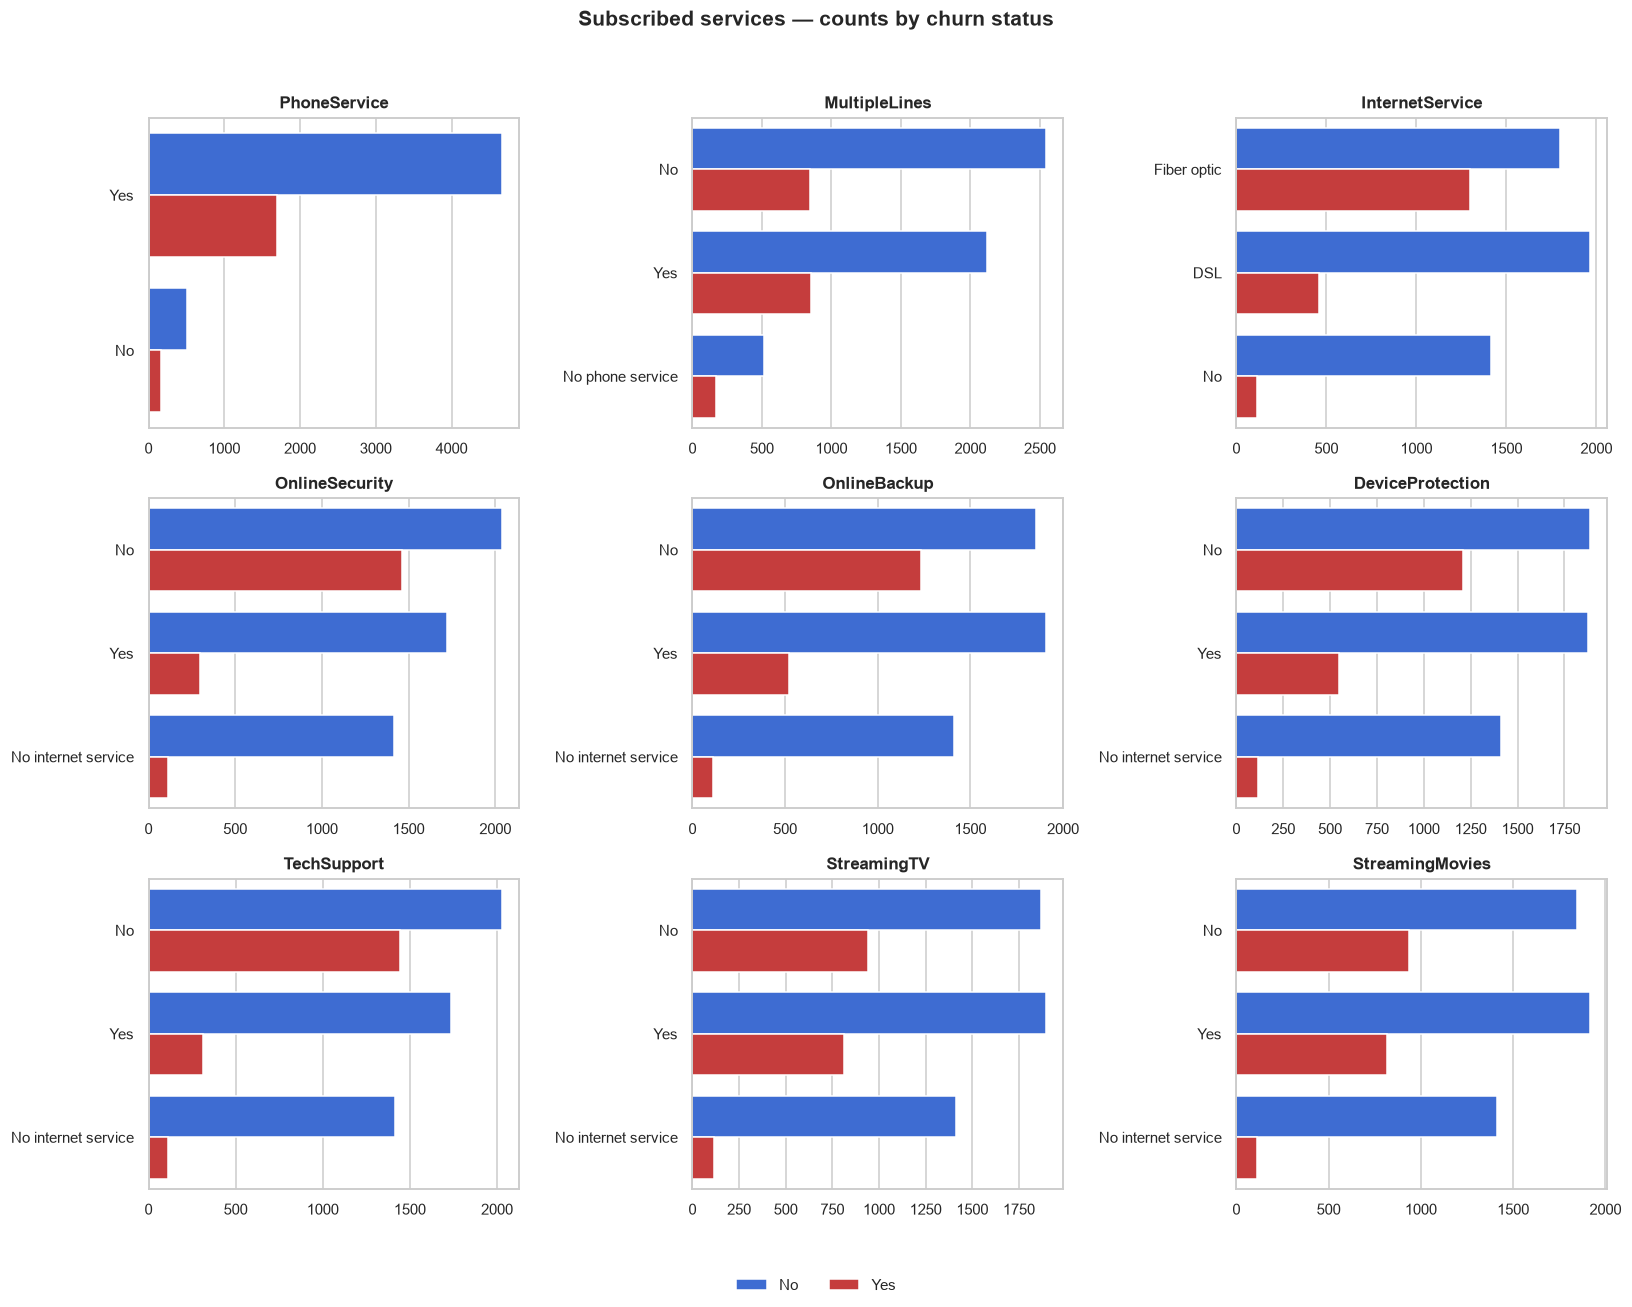

In [14]:
service_cols = ["PhoneService", "MultipleLines", "InternetService", "OnlineSecurity", "OnlineBackup",
                "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
stacked_count_grid(
    service_cols,
    ncols=3, figsize=(15, 12),
    filename="05_services_counts.png",
    title="Subscribed services — counts by churn status",
)

Saved: reports\figures\06_account_counts.png


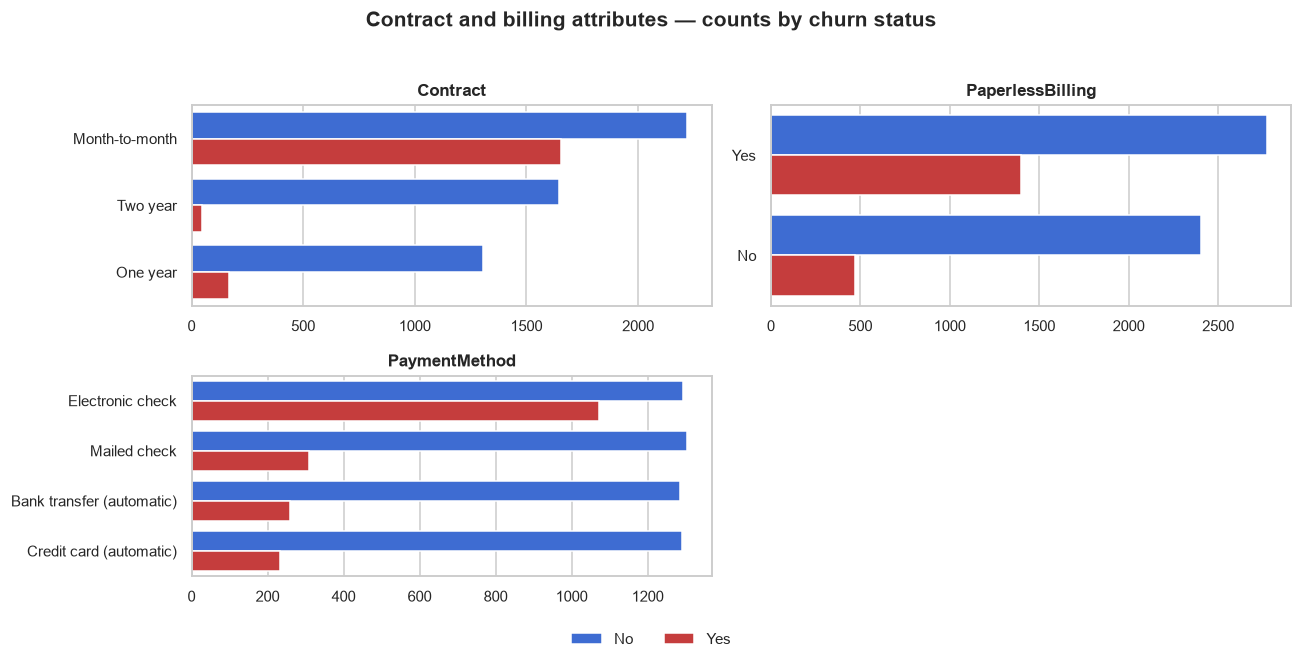

In [15]:
stacked_count_grid(
    ["Contract", "PaperlessBilling", "PaymentMethod"],
    ncols=2, figsize=(12, 6),
    filename="06_account_counts.png",
    title="Contract and billing attributes — counts by churn status",
)

## 5. Churn rates by category

In [16]:
def churn_rate_table(data, cols):
    rows = []
    for col in cols:
        grouped = data.groupby(col, observed=True)["ChurnFlag"].agg(customers="size", churned="sum", churn_rate="mean")
        for level, values in grouped.iterrows():
            rows.append({
                "feature": col,
                "level": str(level),
                "customers": int(values["customers"]),
                "churned": int(values["churned"]),
                "churn_rate_pct": 100 * values["churn_rate"],
            })
    return pd.DataFrame(rows)

all_cat_rates = churn_rate_table(df, categorical_cols)
save_table(all_cat_rates, "churn_rates_by_category.csv")
display(all_cat_rates.head(15).round(2))

driver_spread = (all_cat_rates.groupby("feature")["churn_rate_pct"]
                 .agg(min_rate="min", max_rate="max", spread="max", )
                 .assign(spread=lambda x: x["max_rate"] - x["min_rate"])
                 .sort_values("spread", ascending=False))
display(driver_spread.round(2))

Saved: reports\tables\churn_rates_by_category.csv


,feature,level,customers,churned,churn_rate_pct
0,gender,Female,3488,939,26.92
1,gender,Male,3555,930,26.16
2,Partner,No,3641,1200,32.96
3,Partner,Yes,3402,669,19.66
4,Dependents,No,4933,1543,31.28
5,Dependents,Yes,2110,326,15.45
6,PhoneService,No,682,170,24.93
7,PhoneService,Yes,6361,1699,26.71
8,MultipleLines,No,3390,849,25.04
9,MultipleLines,No phone service,682,170,24.93


,min_rate,max_rate,spread
feature,,,
Contract,2.83,42.71,39.88
InternetService,7.40,41.89,34.49
OnlineSecurity,7.40,41.77,34.36
TechSupport,7.40,41.64,34.23
OnlineBackup,7.40,39.93,32.52
DeviceProtection,7.40,39.13,31.72
PaymentMethod,15.24,45.29,30.04
StreamingMovies,7.40,33.68,26.28
StreamingTV,7.40,33.52,26.12


Saved: reports\figures\07_churn_rates_demographics.png


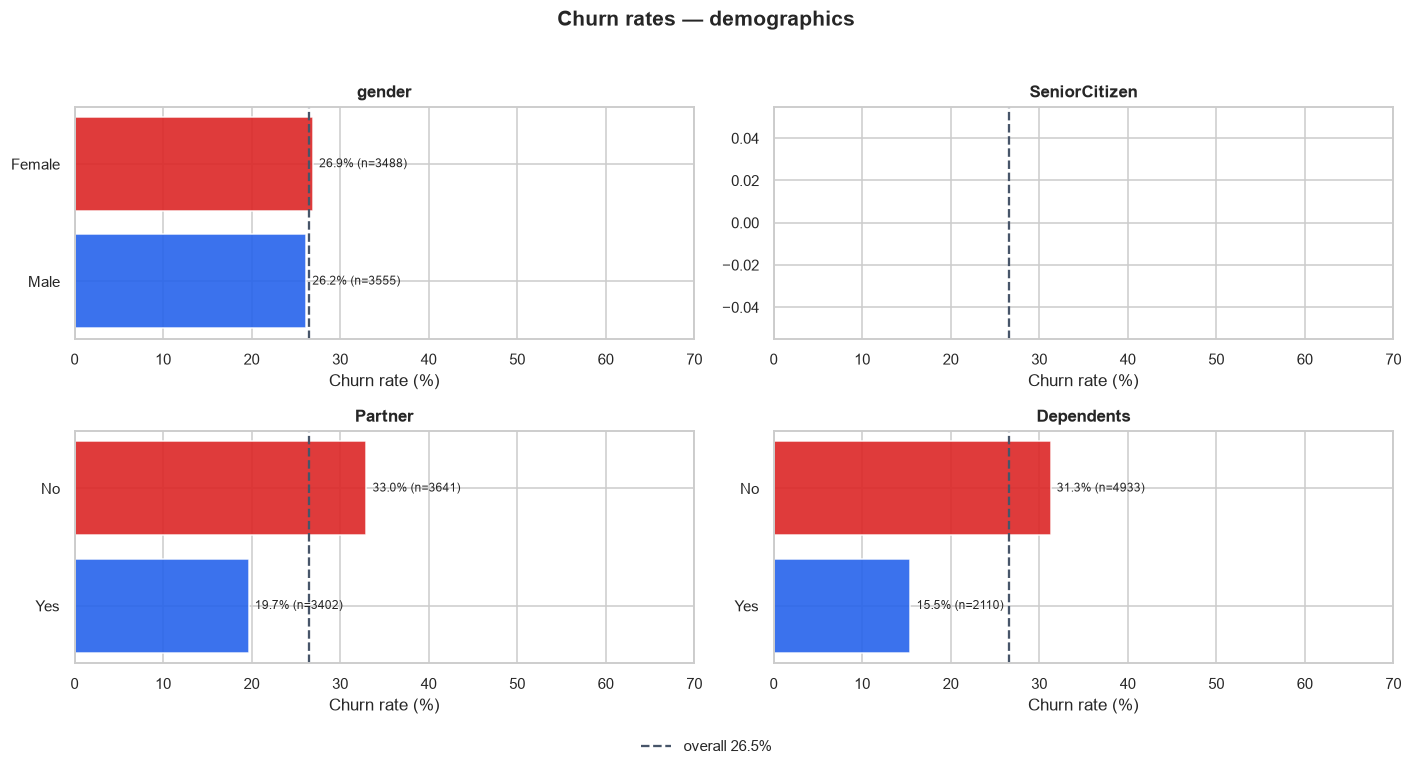

In [17]:
def churn_rate_grid(cols, ncols, figsize, filename, title):
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize)
    axes = np.atleast_1d(axes).ravel()
    baseline = 100 * df["ChurnFlag"].mean()
    for ax, col in zip(axes, cols):
        rates = all_cat_rates[all_cat_rates["feature"] == col].sort_values("churn_rate_pct")
        bars = ax.barh(rates["level"], rates["churn_rate_pct"],
                       color=[RED if v > baseline else BLUE for v in rates["churn_rate_pct"]], alpha=0.9)
        ax.axvline(baseline, color=SLATE, linestyle="--", linewidth=1.5, label=f"overall {baseline:.1f}%")
        for bar, n in zip(bars, rates["customers"]):
            ax.text(bar.get_width() + 0.7, bar.get_y() + bar.get_height()/2, f"{bar.get_width():.1f}% (n={n})",
                    va="center", fontsize=8)
        ax.set_title(col, fontsize=11)
        ax.set_xlabel("Churn rate (%)")
        ax.set_xlim(0, max(70, rates["churn_rate_pct"].max() * 1.28))
        if ax.get_legend() is not None:
            ax.get_legend().remove()
    for ax in axes[len(cols):]:
        ax.set_visible(False)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", frameon=False)
    fig.suptitle(title, fontweight="bold", fontsize=14)
    fig.tight_layout(rect=[0, 0.04, 1, 0.96])
    save_figure(filename)
    plt.show()

churn_rate_grid(["gender", "SeniorCitizen", "Partner", "Dependents"], 2, (13, 7),
                "07_churn_rates_demographics.png", "Churn rates — demographics")

Saved: reports\figures\08_churn_rates_services.png


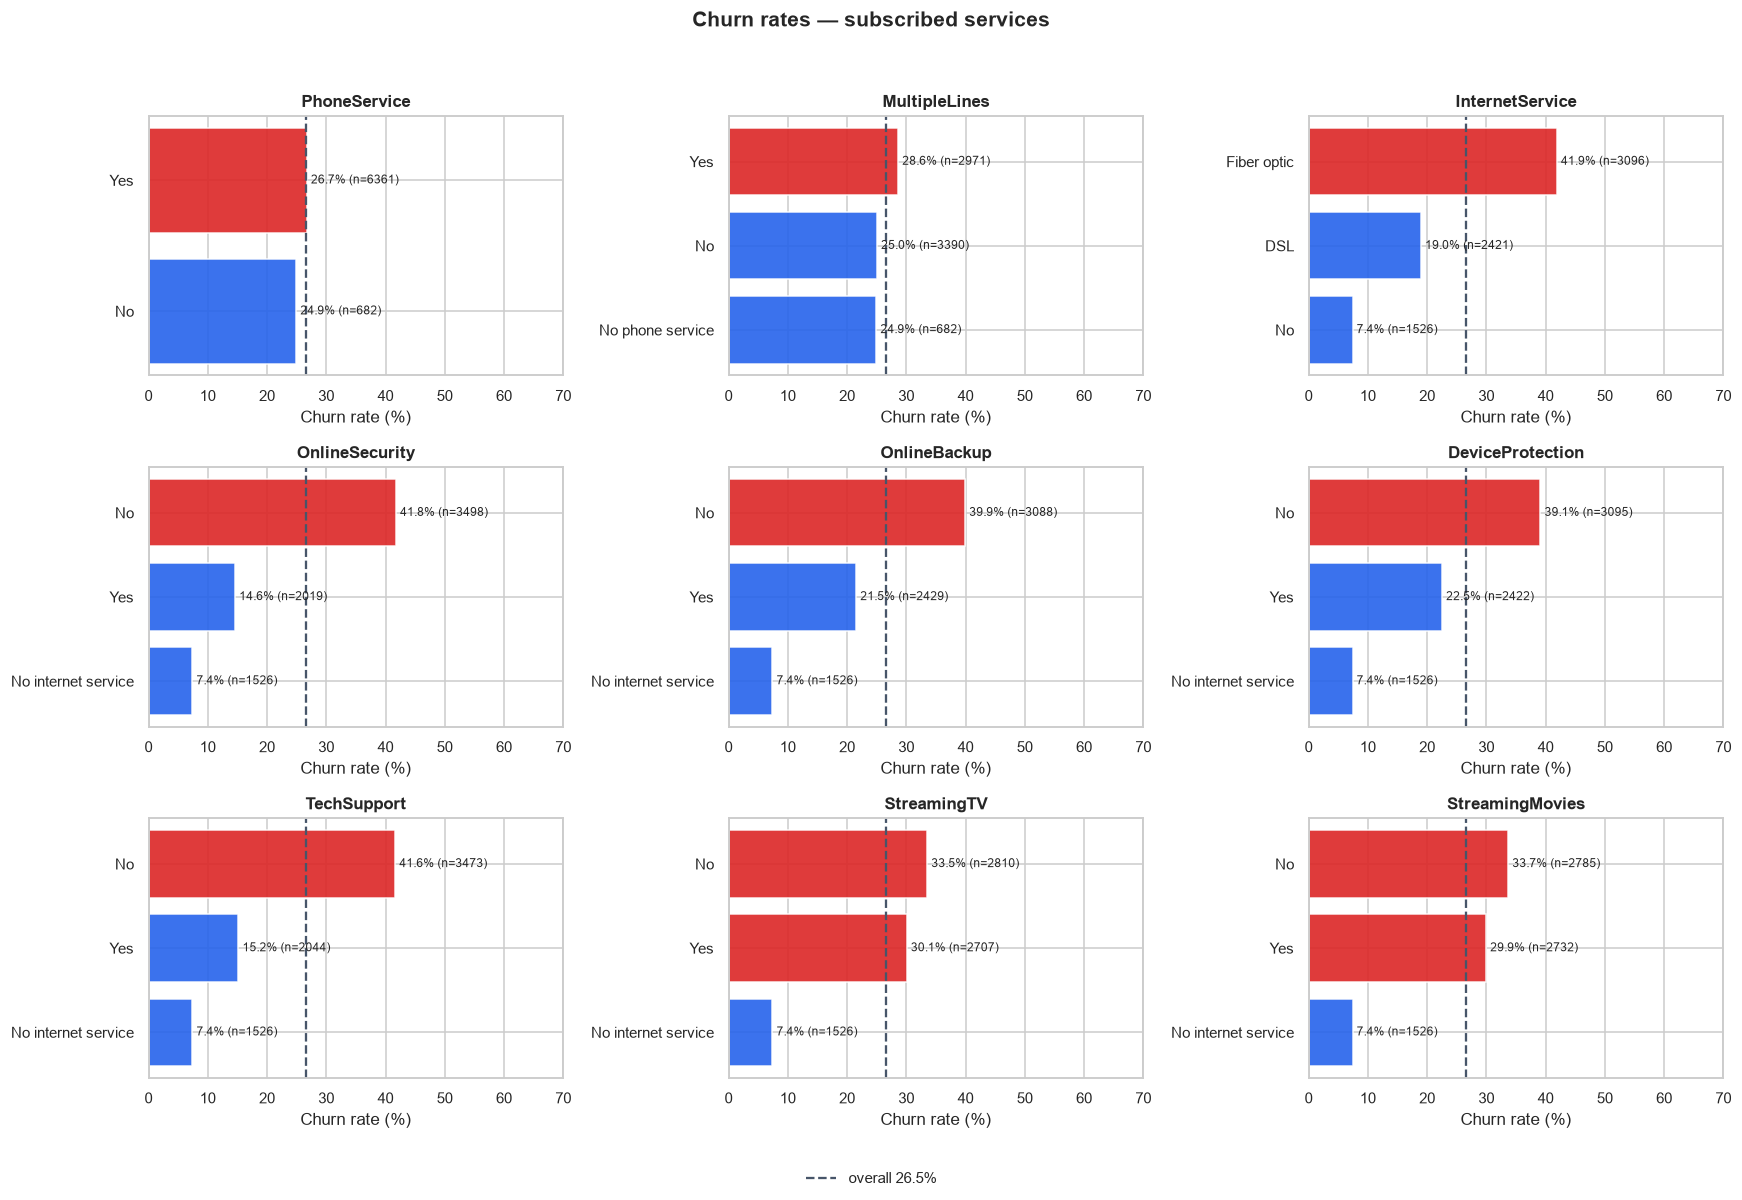

In [18]:
churn_rate_grid(service_cols, 3, (16, 11),
                "08_churn_rates_services.png", "Churn rates — subscribed services")

Saved: reports\figures\09_churn_rates_account.png


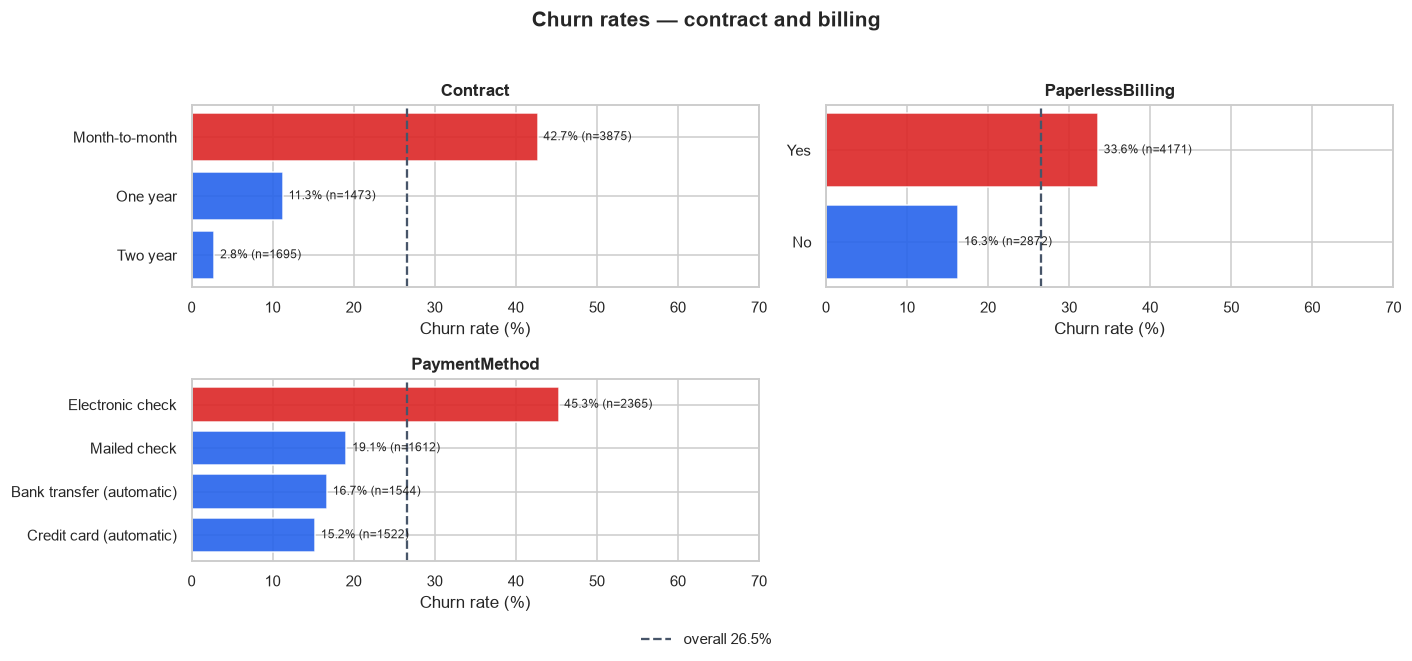

In [19]:
churn_rate_grid(["Contract", "PaperlessBilling", "PaymentMethod"], 2, (13, 6),
                "09_churn_rates_account.png", "Churn rates — contract and billing")

### Key categorical signals

- **Contract:** month-to-month customers churn at 42.71% vs 11.27% (one year) and 2.83% (two year) — the largest spread of any feature.
- **Internet service:** fiber optic churn is 41.89% vs 18.96% for DSL and 7.40% for customers with no internet.
- **Support add-ons:** customers without online security or tech support churn around 41–42%, versus roughly 15% for subscribers who have them.
- **Payment method:** electronic-check users churn at 45.29%, about 3× the rate of automatic credit-card users (15.24%).
- **Demographics:** senior citizens churn at 41.68% vs 23.61% for non-seniors; customers with dependents churn less (15.45% vs 31.28%). Gender is essentially neutral (26.92% female vs 26.16% male).

## 6. Numerical relationships with churn

In [20]:
grouped_numeric = df.groupby("Churn")[["tenure", "MonthlyCharges", "TotalCharges"]].agg(["mean", "median", "std", "count"])
display(grouped_numeric.round(2))

tenure                     MonthlyCharges                      \
        mean median    std count           mean median    std count   
Churn                                                                 
No     37.57   38.0  24.11  5174          61.27  64.43  31.09  5174   
Yes    17.98   10.0  19.53  1869          74.44  79.65  24.67  1869   

      TotalCharges                          
              mean   median      std count  
Churn                                       
No         2555.34  1683.60  2329.46  5163  
Yes        1531.80   703.55  1890.82  1869

Saved: reports\figures\10_violin_numeric_by_churn.png


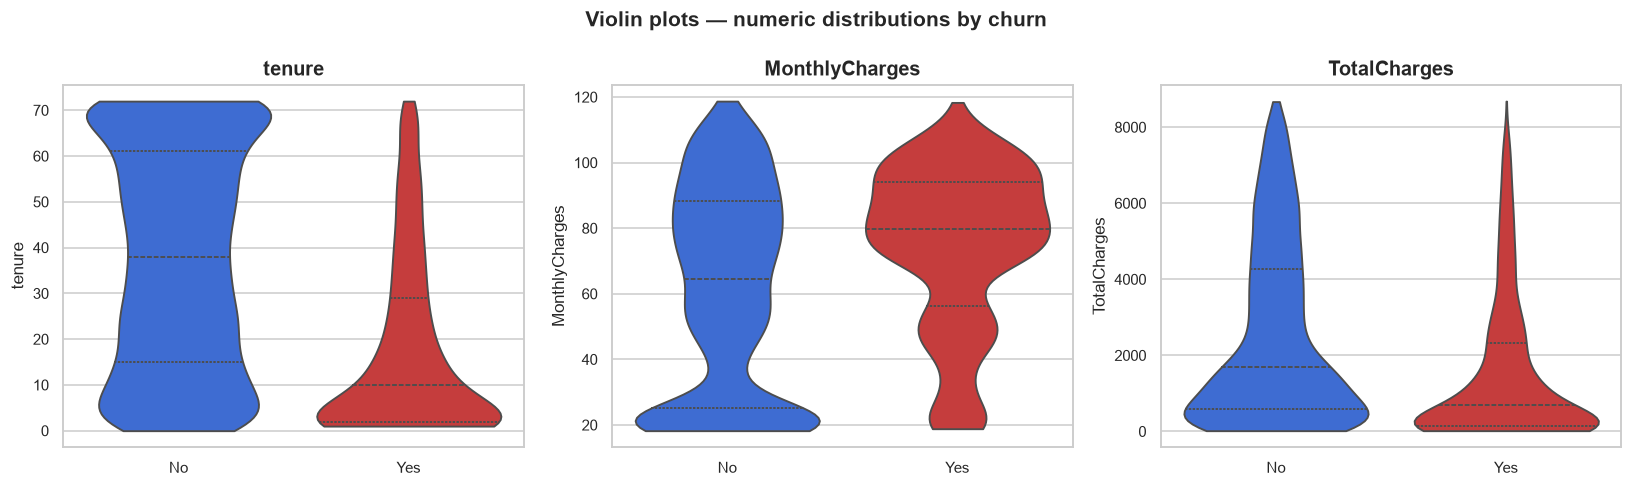

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, col in zip(axes, plot_cols):
    sns.violinplot(data=df.dropna(subset=[col]), x="Churn", y=col, hue="Churn",
                   palette=CHURN_PALETTE, legend=False, inner="quartile", ax=ax, cut=0)
    ax.set_title(col)
    ax.set_xlabel("")
fig.suptitle("Violin plots — numeric distributions by churn", fontweight="bold", fontsize=14)
fig.tight_layout()
save_figure("10_violin_numeric_by_churn.png")
plt.show()

### 6.1 Tenure lifecycle

Tenure is bucketed to reveal the churn lifecycle. The rate falls sharply as customers become established.

,customers,churned,churn_rate_pct
TenureBand,,,
0–3 mo,1062,597,56.21
4–6 mo,419,187,44.63
7–12 mo,705,253,35.89
13–24 mo,1024,294,28.71
25–48 mo,1594,325,20.39
49–72 mo,2239,213,9.51


Saved: reports\tables\churn_by_tenure_band.csv


Saved: reports\figures\11_churn_by_tenure_band.png


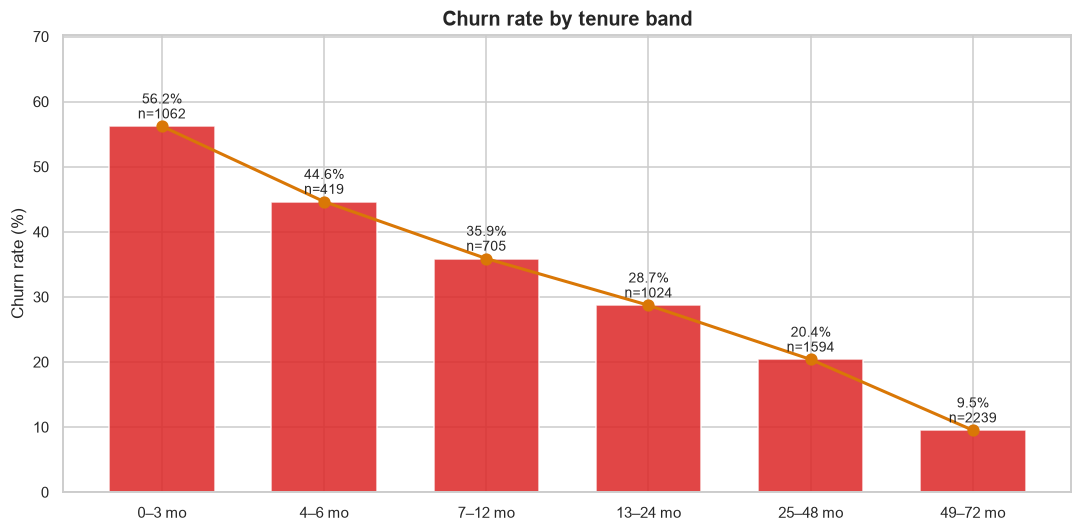

In [22]:
df["TenureBand"] = pd.cut(df["tenure"], bins=[-1, 3, 6, 12, 24, 48, 72],
                          labels=["0–3 mo", "4–6 mo", "7–12 mo", "13–24 mo", "25–48 mo", "49–72 mo"])
tenure_rates = (df.groupby("TenureBand", observed=True)["ChurnFlag"]
                .agg(customers="size", churned="sum", churn_rate="mean"))
tenure_rates["churn_rate_pct"] = 100 * tenure_rates["churn_rate"]
display(tenure_rates[["customers", "churned", "churn_rate_pct"]].round(2))
save_table(tenure_rates.reset_index().assign(TenureBand=lambda x: x["TenureBand"].astype(str)), "churn_by_tenure_band.csv")

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(tenure_rates))
bars = ax.bar(x, tenure_rates["churn_rate_pct"], color=RED, alpha=0.85, width=0.65)
ax.plot(x, tenure_rates["churn_rate_pct"], color=AMBER, marker="o", linewidth=2, markersize=7)
for i, (bar, n) in enumerate(zip(bars, tenure_rates["customers"])):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1.2,
            f"{bar.get_height():.1f}%\nn={n}", ha="center", fontsize=9)
ax.set_xticks(x, tenure_rates.index.astype(str))
ax.set_ylabel("Churn rate (%)")
ax.set_title("Churn rate by tenure band")
ax.set_ylim(0, max(tenure_rates["churn_rate_pct"]) * 1.25)
fig.tight_layout()
save_figure("11_churn_by_tenure_band.png")
plt.show()

**Interpretation.** More than half (56.21%) of customers in their first three months churn. The rate drops to 35.89% by months 7–12, 20.39% at 25–48 months, and 9.51% after four years. Onboarding and early-value delivery are the most important intervention windows.

### 6.2 Monthly charges — the confounding effect of internet type

A naive look at monthly charges suggests a non-monotonic relationship. Splitting by internet service reveals why: low-charge customers are mostly DSL/no-internet users, while the high-charge band is dominated by fiber optic customers who have structurally higher churn.

InternetService,DSL,Fiber optic,No
MonthlyChargeBand,,,
<35,36.36,NaN,7.4
35–50,30.50,NaN,NaN
50–65,18.22,NaN,NaN
65–80,9.30,56.52,NaN
80+,2.90,37.57,NaN


Saved: reports\tables\churn_by_charge_band_and_internet.csv


Saved: reports\figures\12_churn_by_charge_band_internet.png


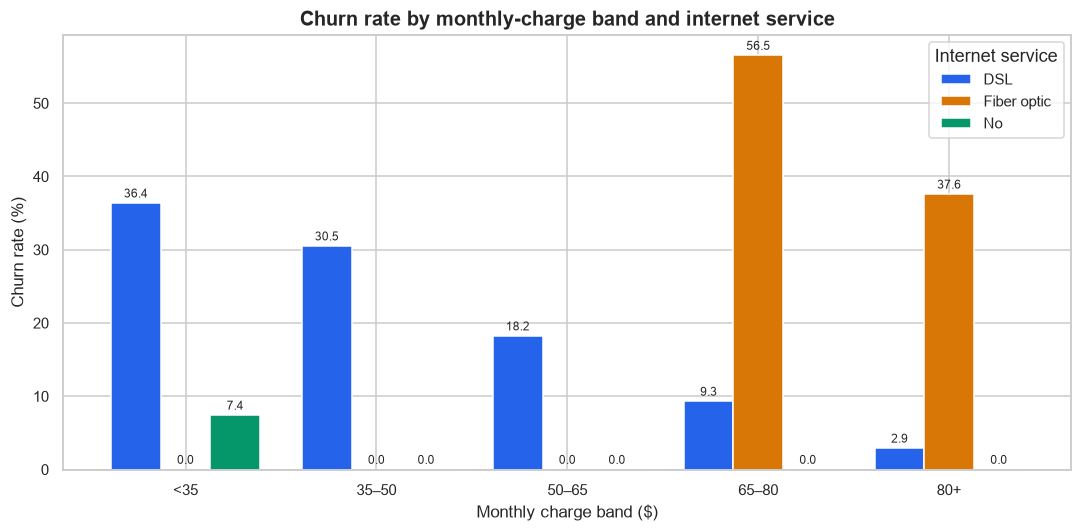

In [23]:
df["MonthlyChargeBand"] = pd.cut(df["MonthlyCharges"], bins=[0, 35, 50, 65, 80, np.inf],
                                 labels=["<35", "35–50", "50–65", "65–80", "80+"])
charge_rates = (df.pivot_table(index="MonthlyChargeBand", columns="InternetService", values="ChurnFlag",
                               aggfunc="mean", observed=True) * 100).round(2)
display(charge_rates)
save_table(charge_rates.reset_index().assign(MonthlyChargeBand=lambda x: x["MonthlyChargeBand"].astype(str)),
           "churn_by_charge_band_and_internet.csv")

fig, ax = plt.subplots(figsize=(10, 5))
charge_rates.plot(kind="bar", ax=ax, color=[BLUE, AMBER, GREEN], width=0.78)
ax.set_title("Churn rate by monthly-charge band and internet service")
ax.set_ylabel("Churn rate (%)")
ax.set_xlabel("Monthly charge band ($)")
ax.set_xticklabels([str(v) for v in charge_rates.index], rotation=0)
ax.legend(title="Internet service")
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", padding=2, fontsize=8)
fig.tight_layout()
save_figure("12_churn_by_charge_band_internet.png")
plt.show()

Saved: reports\figures\13_monthly_charge_kde_by_internet.png


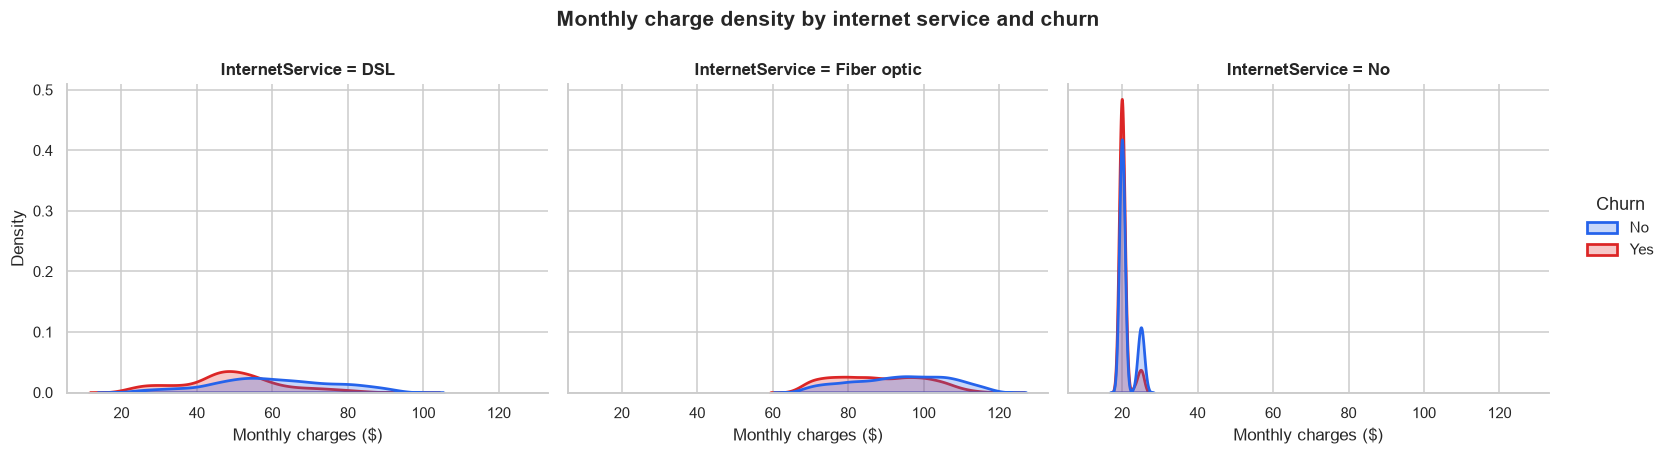

In [24]:
g = sns.displot(
    data=df,
    x="MonthlyCharges",
    hue="Churn",
    col="InternetService",
    kind="kde",
    fill=True,
    alpha=0.25,
    linewidth=1.8,
    palette=CHURN_PALETTE,
    common_norm=False,
    height=4.2,
    aspect=1.15,
)
g.fig.suptitle("Monthly charge density by internet service and churn", fontweight="bold", fontsize=14)
g.fig.subplots_adjust(top=0.82)
g.set_axis_labels("Monthly charges ($)", "Density")
path = FIG_DIR / "13_monthly_charge_kde_by_internet.png"
g.fig.savefig(path, dpi=160, bbox_inches="tight", facecolor="white")
print(f"Saved: {path.relative_to(PROJECT_ROOT)}")
plt.show()

**Interpretation.** Fiber-optic customers are concentrated in the $65+ bands and churn at 56.5% in the $65–80 band and 37.6% at $80+. Within DSL, the opposite pattern holds: churn falls from 36.4% below $35 to 2.9% above $80. Price alone is therefore not the driver — the fiber product/experience and its associated contract/payment mix are the real risk factors.

## 7. Statistical association and correlation

,feature,cramers_v,p_value,significant_at_5pct
12,Contract,0.4098,0.0000,True
6,OnlineSecurity,0.3470,0.0000,True
9,TechSupport,0.3425,0.0000,True
5,InternetService,0.3220,0.0000,True
14,PaymentMethod,0.3027,0.0000,True
7,OnlineBackup,0.2919,0.0000,True
8,DeviceProtection,0.2811,0.0000,True
11,StreamingMovies,0.2304,0.0000,True
10,StreamingTV,0.2299,0.0000,True
13,PaperlessBilling,0.1911,0.0000,True


Saved: reports\tables\categorical_association_with_churn.csv


Saved: reports\figures\14_categorical_association.png


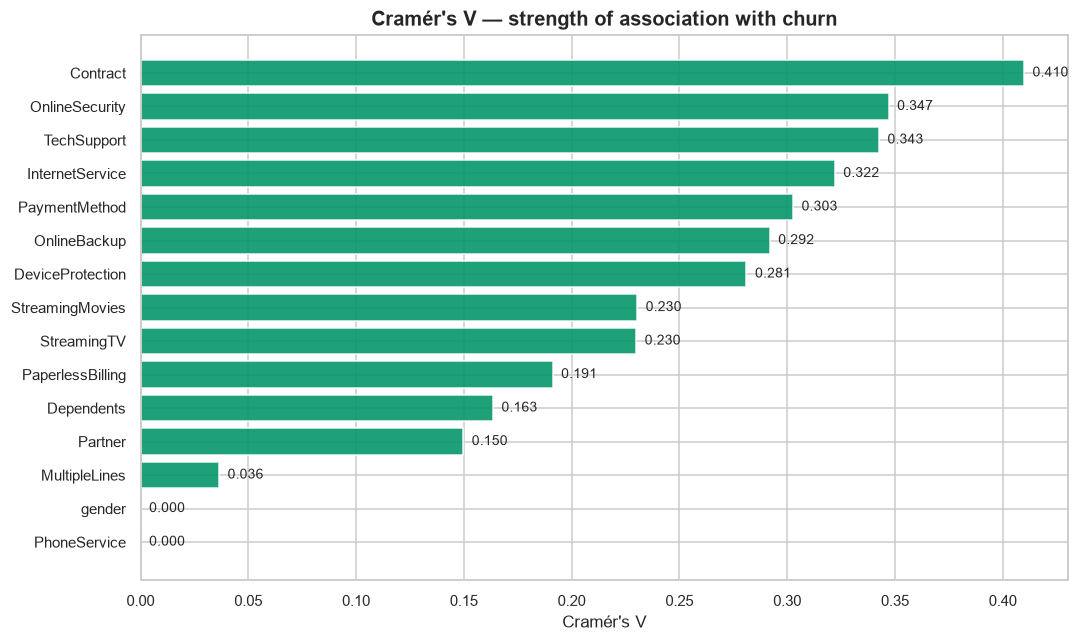

In [25]:
def cramers_v(x, y):
    table = pd.crosstab(x, y)
    chi2, p_value, dof, expected = stats.chi2_contingency(table)
    n = table.to_numpy().sum()
    phi2 = chi2 / n
    r, k = table.shape
    bias_corrected = max(0, phi2 - (k - 1) * (r - 1) / max(1, n - 1))
    r_corr = r - (r - 1) ** 2 / max(1, n - 1)
    k_corr = k - (k - 1) ** 2 / max(1, n - 1)
    v = np.sqrt(bias_corrected / max(1e-12, min(k_corr - 1, r_corr - 1)))
    return v, p_value

association_rows = []
for col in categorical_cols:
    v, p = cramers_v(df[col], df["Churn"])
    association_rows.append({"feature": col, "cramers_v": v, "p_value": p})
association = pd.DataFrame(association_rows).sort_values("cramers_v", ascending=False)
association["significant_at_5pct"] = association["p_value"] < 0.05
display(association.round(4))
save_table(association, "categorical_association_with_churn.csv")

fig, ax = plt.subplots(figsize=(10, 6))
plot_assoc = association.sort_values("cramers_v")
colors = [GREEN if s else SLATE for s in plot_assoc["significant_at_5pct"]]
ax.barh(plot_assoc["feature"], plot_assoc["cramers_v"], color=colors, alpha=0.9)
for i, v in enumerate(plot_assoc["cramers_v"]):
    ax.text(v + 0.004, i, f"{v:.3f}", va="center", fontsize=9)
ax.set_title("Cramér's V — strength of association with churn")
ax.set_xlabel("Cramér's V")
fig.tight_layout()
save_figure("14_categorical_association.png")
plt.show()

Saved: reports\figures\15_correlation_heatmap.png


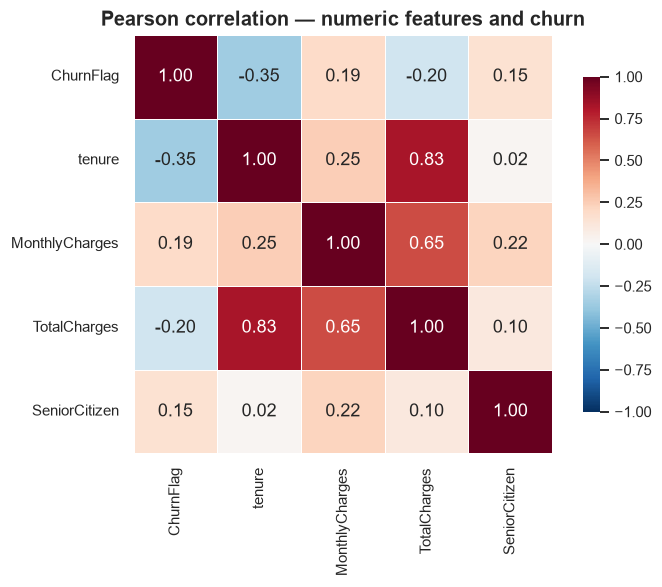

Correlation with churn flag:


,pearson_r
tenure,-0.352
TotalCharges,-0.199
SeniorCitizen,0.151
MonthlyCharges,0.193


In [26]:
corr_numeric = df[["ChurnFlag", "tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen"]].corr()
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr_numeric, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Pearson correlation — numeric features and churn")
fig.tight_layout()
save_figure("15_correlation_heatmap.png")
plt.show()

print("Correlation with churn flag:")
display(corr_numeric["ChurnFlag"].drop("ChurnFlag").sort_values().round(3).to_frame("pearson_r"))

,correlation_with_churn
tenure,-0.352
Contract_Two year,-0.302
TenureBand_49–72 mo,-0.263
OnlineSecurity_No internet service,-0.228
TotalCharges,-0.199
Contract_One year,-0.178
MultipleLines_Yes,0.040
StreamingMovies_Yes,0.061
StreamingTV_Yes,0.063
TenureBand_7–12 mo,0.071


Saved: reports\figures\16_encoded_correlations.png


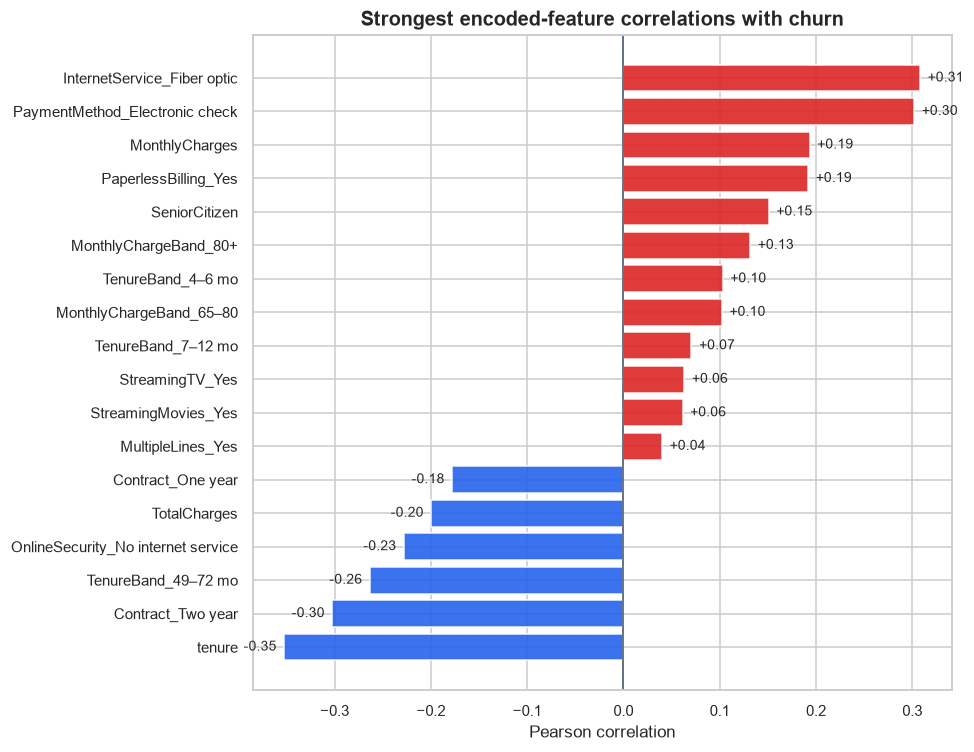

In [27]:
encoded = pd.get_dummies(df.drop(columns=[ID_COL, TARGET, "ChurnFlag"]), drop_first=True).astype(float)
encoded["ChurnFlag"] = df["ChurnFlag"]
encoded_corr = encoded.corr(numeric_only=True)["ChurnFlag"].drop("ChurnFlag").sort_values()
top_corr = pd.concat([encoded_corr.head(12), encoded_corr.tail(12)]).drop_duplicates().sort_values()
display(top_corr.round(3).to_frame("correlation_with_churn"))

fig, ax = plt.subplots(figsize=(9, 7))
colors = [RED if v > 0 else BLUE for v in top_corr.values]
ax.barh(top_corr.index, top_corr.values, color=colors, alpha=0.9)
ax.axvline(0, color=SLATE, linewidth=1)
for i, v in enumerate(top_corr.values):
    ax.text(v + (0.008 if v >= 0 else -0.008), i, f"{v:+.2f}",
            va="center", ha="left" if v >= 0 else "right", fontsize=9)
ax.set_title("Strongest encoded-feature correlations with churn")
ax.set_xlabel("Pearson correlation")
fig.tight_layout()
save_figure("16_encoded_correlations.png")
plt.show()

**Association ranking.** Contract, online security, tech support, internet service, and payment method have the strongest categorical associations with churn (Cramér's V ≈ 0.30–0.41), while gender and phone service are essentially unrelated. Numerically, tenure has the strongest protective relationship (r = −0.35); monthly charges are mildly positive (r = +0.19) and total charges are confounded by tenure (r = −0.20).

## 8. Interaction and segment analysis

InternetService,DSL,Fiber optic,No
Contract,,,
Month-to-month,32.22,54.61,18.89
One year,9.30,19.29,2.47
Two year,1.91,7.23,0.78


Saved: reports\figures\17_contract_internet_heatmap.png


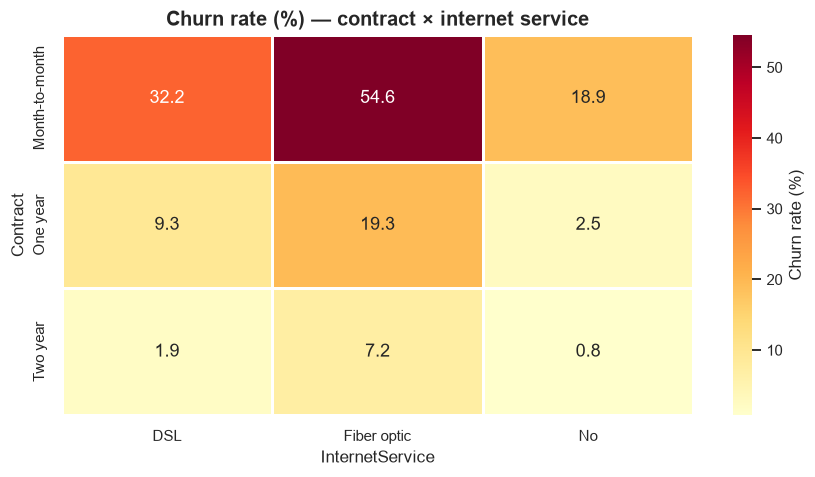

In [28]:
contract_internet = (df.pivot_table(index="Contract", columns="InternetService", values="ChurnFlag",
                                    aggfunc="mean", observed=True) * 100).round(2)
display(contract_internet)

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.heatmap(contract_internet, annot=True, fmt=".1f", cmap="YlOrRd", linewidths=0.7,
            cbar_kws={"label": "Churn rate (%)"}, ax=ax)
ax.set_title("Churn rate (%) — contract × internet service")
fig.tight_layout()
save_figure("17_contract_internet_heatmap.png")
plt.show()

Contract,Month-to-month,One year,Two year
TenureBand,,,
0–3 mo,58.05,9.52,0.00
4–6 mo,47.68,11.11,0.00
7–12 mo,42.00,10.59,0.00
13–24 mo,37.72,8.12,0.00
25–48 mo,32.92,10.62,2.19
49–72 mo,26.02,12.93,3.33


Saved: reports\figures\18_tenure_contract_heatmap.png


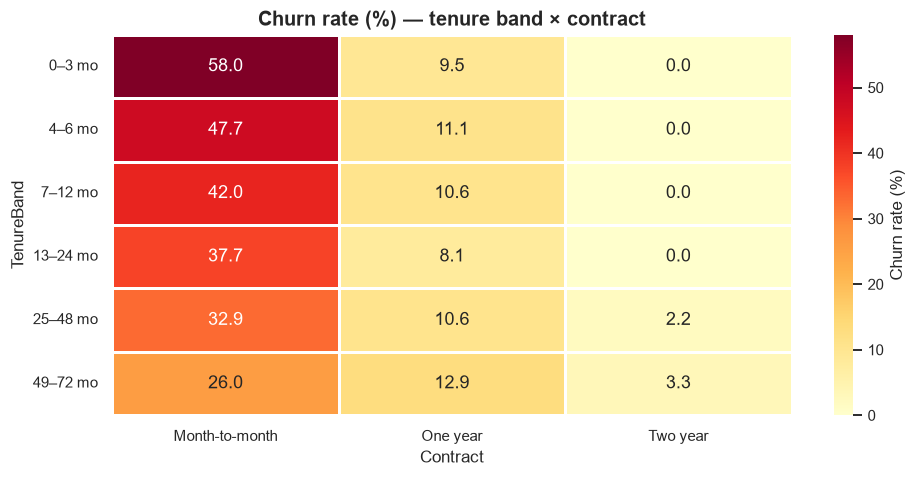

In [29]:
tenure_contract = (df.pivot_table(index="TenureBand", columns="Contract", values="ChurnFlag",
                                  aggfunc="mean", observed=True) * 100).round(2)
display(tenure_contract)

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.heatmap(tenure_contract, annot=True, fmt=".1f", cmap="YlOrRd", linewidths=0.7,
            cbar_kws={"label": "Churn rate (%)"}, ax=ax)
ax.set_title("Churn rate (%) — tenure band × contract")
fig.tight_layout()
save_figure("18_tenure_contract_heatmap.png")
plt.show()

InternetService,DSL,Fiber optic,No
PaymentMethod,,,
Bank transfer (automatic),9.36,28.95,5.42
Credit card (automatic),12.12,25.29,2.72
Electronic check,31.94,53.23,12.30
Mailed check,20.72,42.64,9.58


Saved: reports\figures\19_payment_internet_heatmap.png


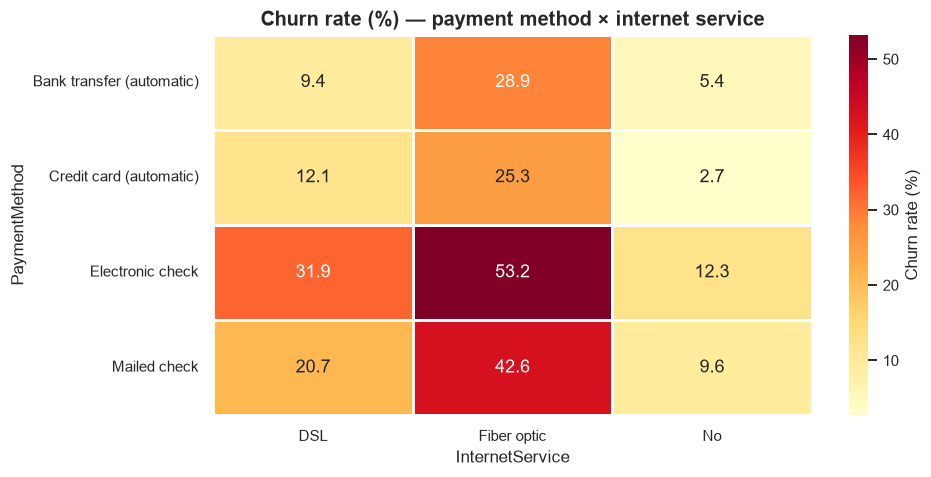

In [30]:
payment_internet = (df.pivot_table(index="PaymentMethod", columns="InternetService", values="ChurnFlag",
                                   aggfunc="mean", observed=True) * 100).round(2)
display(payment_internet)

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.heatmap(payment_internet, annot=True, fmt=".1f", cmap="YlOrRd", linewidths=0.7,
            cbar_kws={"label": "Churn rate (%)"}, ax=ax)
ax.set_title("Churn rate (%) — payment method × internet service")
fig.tight_layout()
save_figure("19_payment_internet_heatmap.png")
plt.show()

InternetService,DSL,Fiber optic,No
Non-senior,17.62,39.91,7.33
Senior,30.12,47.29,9.62


Saved: reports\figures\20_senior_internet_churn.png


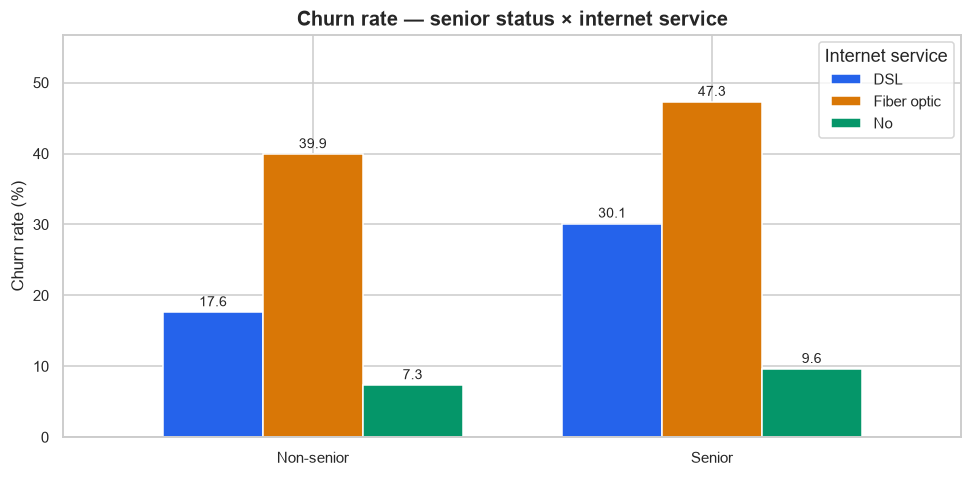

In [31]:
senior_internet = (df.pivot_table(index="SeniorCitizen", columns="InternetService", values="ChurnFlag",
                                  aggfunc="mean", observed=True) * 100).round(2)
senior_internet.index = ["Non-senior", "Senior"]
display(senior_internet)

fig, ax = plt.subplots(figsize=(9, 4.5))
senior_internet.plot(kind="bar", ax=ax, color=[BLUE, AMBER, GREEN], width=0.75)
ax.set_title("Churn rate — senior status × internet service")
ax.set_ylabel("Churn rate (%)")
ax.set_xlabel("")
ax.set_xticklabels(senior_internet.index, rotation=0)
ax.legend(title="Internet service")
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f", padding=2, fontsize=9)
ax.set_ylim(0, senior_internet.values.max() * 1.2)
fig.tight_layout()
save_figure("20_senior_internet_churn.png")
plt.show()

### 8.1 Service adoption and churn

Counting the number of subscribed services (phone, multiple lines, security, backup, protection, support, streaming TV/movies) shows a strong protective effect for deeply engaged households. The lowest counts are dominated by customers who subscribe to no internet service at all, so this view is interpreted alongside product type.

,customers,churned,churn_rate_pct
ServicesSubscribed,,,
0,80,35,43.75
1,1701,359,21.11
2,1188,390,32.83
3,965,352,36.48
4,922,289,31.34
5,908,232,25.55
6,676,152,22.49
7,395,49,12.41
8,208,11,5.29


Saved: reports\figures\21_services_adoption_churn.png


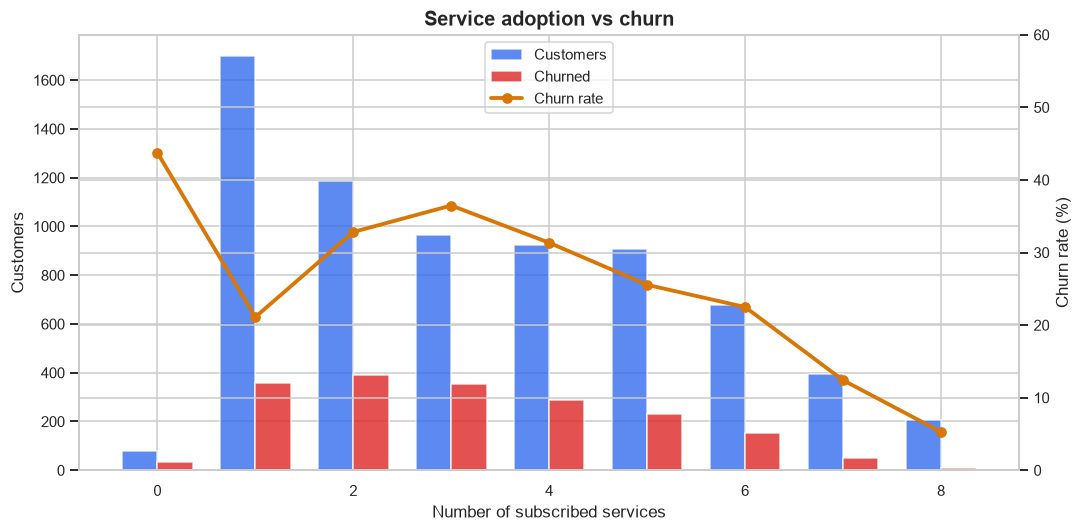

In [32]:
service_cols_binary = ["PhoneService", "MultipleLines", "OnlineSecurity", "OnlineBackup",
                       "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
df["ServicesSubscribed"] = sum((df[c] == "Yes").astype(int) for c in service_cols_binary)
services_summary = (df.groupby("ServicesSubscribed")["ChurnFlag"]
                    .agg(customers="size", churned="sum", churn_rate="mean"))
services_summary["churn_rate_pct"] = 100 * services_summary["churn_rate"]
display(services_summary[["customers", "churned", "churn_rate_pct"]].round(2))

fig, ax1 = plt.subplots(figsize=(10, 5))
x = services_summary.index
ax1.bar(x - 0.18, services_summary["customers"], width=0.36, color=BLUE, alpha=0.75, label="Customers")
ax1.bar(x + 0.18, services_summary["churned"], width=0.36, color=RED, alpha=0.8, label="Churned")
ax1.set_xlabel("Number of subscribed services")
ax1.set_ylabel("Customers")
ax2 = ax1.twinx()
ax2.plot(x, services_summary["churn_rate_pct"], color=AMBER, marker="o", linewidth=2.5, label="Churn rate")
ax2.set_ylabel("Churn rate (%)")
ax2.set_ylim(0, 60)
ax1.set_title("Service adoption vs churn")
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper center")
fig.tight_layout()
save_figure("21_services_adoption_churn.png")
plt.show()

### 8.2 Highest- and lowest-risk customer segments

Segments are defined by the combination of contract, internet service, and payment method. Only groups with at least 50 customers are reported to avoid unstable small-sample rates.

TOP 10 HIGHEST-RISK SEGMENTS (n >= 50)


customers  churned  \
Contract       InternetService PaymentMethod                                   
Month-to-month Fiber optic     Electronic check                1307      789   
                               Mailed check                     201      102   
                               Bank transfer (automatic)        327      149   
                               Credit card (automatic)          293      122   
               DSL             Electronic check                 474      192   
                               Mailed check                     367      113   
                               Credit card (automatic)          185       50   
One year       Fiber optic     Electronic check                 196       51   
Month-to-month No              Mailed check                     325       67   
                               Bank transfer (automatic)         65       13   

                                                          churn_rate_pct  
Contract       InternetService PaymentMethod                              
Month-to-month Fiber optic     Electronic check                    60.37  
                               Mailed check                        50.75  
                               Bank transfer (automatic)           45.57  
                               Credit card (automatic)             41.64  
               DSL             Electronic check                    40.51  
                               Mailed check                        30.79  
                               Credit card (automatic)             27.03  
One year       Fiber optic     Electronic check                    26.02  
Month-to-month No              Mailed check                        20.62  
                               Bank transfer (automatic)           20.00

TOP 10 LOWEST-RISK SEGMENTS (n >= 50)


customers  churned  \
Contract InternetService PaymentMethod                                   
One year No              Bank transfer (automatic)         89        4   
Two year Fiber optic     Credit card (automatic)          154        6   
         DSL             Credit card (automatic)          237        5   
                         Bank transfer (automatic)        224        3   
One year No              Credit card (automatic)           76        1   
                         Mailed check                     164        2   
Two year No              Credit card (automatic)          190        2   
                         Mailed check                     252        2   
                         Bank transfer (automatic)        178        1   
         DSL             Mailed check                     109        0   

                                                    churn_rate_pct  
Contract InternetService PaymentMethod                              
One year No              Bank transfer (automatic)            4.49  
Two year Fiber optic     Credit card (automatic)              3.90  
         DSL             Credit card (automatic)              2.11  
                         Bank transfer (automatic)            1.34  
One year No              Credit card (automatic)              1.32  
                         Mailed check                         1.22  
Two year No              Credit card (automatic)              1.05  
                         Mailed check                         0.79  
                         Bank transfer (automatic)            0.56  
         DSL             Mailed check                         0.00

Saved: reports\tables\churn_by_contract_internet_payment_segment.csv


Saved: reports\figures\22_high_low_risk_segments.png


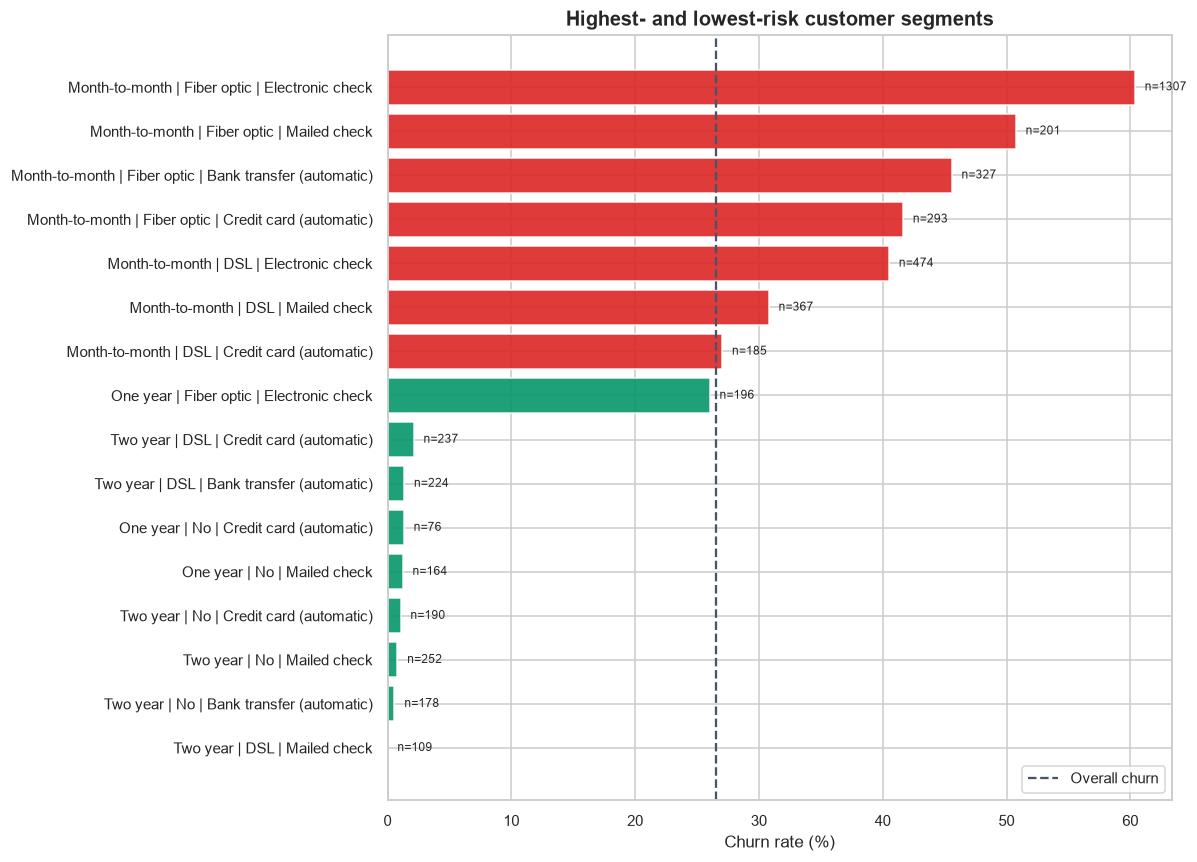

In [33]:
segments = (df.groupby(["Contract", "InternetService", "PaymentMethod"], observed=True)["ChurnFlag"]
            .agg(customers="size", churned="sum", churn_rate="mean"))
segments = segments[segments["customers"] >= 50].copy()
segments["churn_rate_pct"] = 100 * segments["churn_rate"]
segments = segments.sort_values("churn_rate_pct", ascending=False)

print("TOP 10 HIGHEST-RISK SEGMENTS (n >= 50)")
display(segments[["customers", "churned", "churn_rate_pct"]].head(10).round(2))
print("TOP 10 LOWEST-RISK SEGMENTS (n >= 50)")
display(segments[["customers", "churned", "churn_rate_pct"]].tail(10).round(2))
save_table(segments.reset_index()[["Contract", "InternetService", "PaymentMethod", "customers", "churned", "churn_rate_pct"]].round(2),
           "churn_by_contract_internet_payment_segment.csv")

plot_segments = pd.concat([segments.head(8), segments.tail(8)])
labels = [f"{c} | {i} | {p}" for c, i, p in plot_segments.index]
fig, ax = plt.subplots(figsize=(11, 8))
colors = [RED if v > 100 * df["ChurnFlag"].mean() else GREEN for v in plot_segments["churn_rate_pct"]]
bars = ax.barh(labels[::-1], plot_segments["churn_rate_pct"].values[::-1], color=colors[::-1], alpha=0.9)
ax.axvline(100 * df["ChurnFlag"].mean(), color=SLATE, linestyle="--", label="Overall churn")
for bar, n in zip(bars, plot_segments["customers"].values[::-1]):
    ax.text(bar.get_width() + 0.8, bar.get_y() + bar.get_height()/2, f"n={n}", va="center", fontsize=8)
ax.set_title("Highest- and lowest-risk customer segments")
ax.set_xlabel("Churn rate (%)")
ax.legend(loc="lower right")
fig.tight_layout()
save_figure("22_high_low_risk_segments.png")
plt.show()

**Highest-risk segment.** Month-to-month fiber-optic customers paying by electronic check churn at **60.37%** (1,307 customers) — more than twice the overall rate. This single segment accounts for a large share of all churn and is the clearest target for a retention pilot.

**Lowest-risk segments.** Two-year DSL customers on automatic payment methods churn at roughly 0.6–2.1%, confirming the protective combination of long commitment, DSL product, and automatic billing.

## 9. Revenue impact

In [34]:
df["MonthlyRevenueAtRisk"] = np.where(df["ChurnFlag"] == 1, df["MonthlyCharges"], 0.0)
mrr_total = df["MonthlyCharges"].sum()
mrr_at_risk = df["MonthlyRevenueAtRisk"].sum()
avg_churn_charge = df.loc[df["ChurnFlag"] == 1, "MonthlyCharges"].mean()
avg_retained_charge = df.loc[df["ChurnFlag"] == 0, "MonthlyCharges"].mean()

revenue_summary = pd.DataFrame({
    "metric": [
        "Total monthly recurring revenue (MRR)",
        "MRR associated with churned customers",
        "Share of MRR lost to churn (%)",
        "Avg monthly charge — churned ($)",
        "Avg monthly charge — retained ($)",
        "Historical total charges from churned customers ($)",
    ],
    "value": [
        mrr_total, mrr_at_risk, 100 * mrr_at_risk / mrr_total,
        avg_churn_charge, avg_retained_charge,
        df.loc[df["ChurnFlag"] == 1, "TotalCharges"].sum(),
    ],
})
display(revenue_summary.round(2))

,metric,value
0,Total monthly recurring revenue (MRR),456116.60
1,MRR associated with churned customers,139130.85
2,Share of MRR lost to churn (%),30.50
3,Avg monthly charge — churned ($),74.44
4,Avg monthly charge — retained ($),61.27
5,Historical total charges from churned customer...,2862926.90


,customers,churned,total_mrr,mrr_at_risk,churn_rate_pct,mrr_at_risk_pct
Contract,,,,,,
Month-to-month,3875,1655,257294.15,120847.10,42.71,46.97
One year,1473,166,95816.60,14118.45,11.27,14.73
Two year,1695,48,103005.85,4165.30,2.83,4.04


Saved: reports\figures\23_revenue_at_risk.png


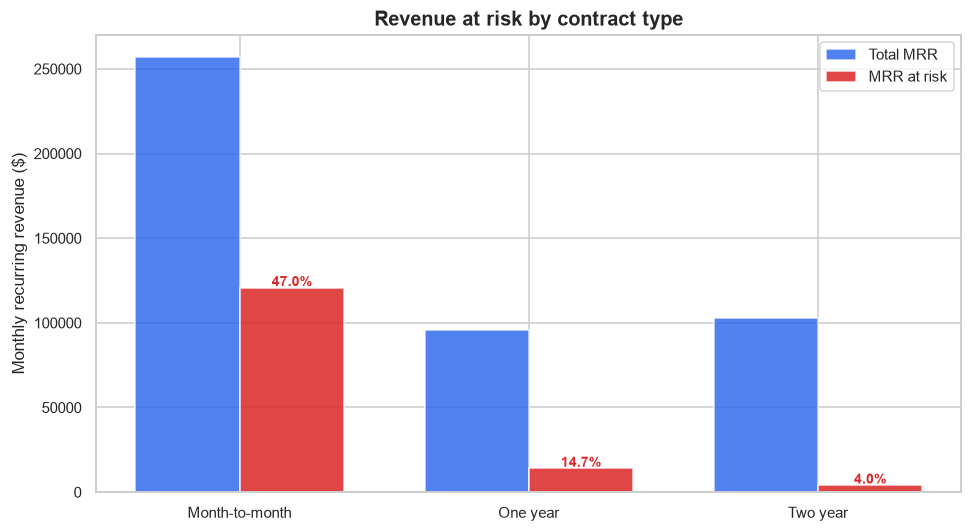

In [35]:
revenue_by_contract = (df.assign(MonthlyRevenueAtRisk=np.where(df["ChurnFlag"] == 1, df["MonthlyCharges"], 0.0))
                       .groupby("Contract")
                       .agg(customers=("ChurnFlag", "size"), churned=("ChurnFlag", "sum"),
                            total_mrr=("MonthlyCharges", "sum"), mrr_at_risk=("MonthlyRevenueAtRisk", "sum")))
revenue_by_contract["churn_rate_pct"] = 100 * revenue_by_contract["churned"] / revenue_by_contract["customers"]
revenue_by_contract["mrr_at_risk_pct"] = 100 * revenue_by_contract["mrr_at_risk"] / revenue_by_contract["total_mrr"]
display(revenue_by_contract.round(2))

fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(revenue_by_contract))
ax.bar(x - 0.18, revenue_by_contract["total_mrr"], width=0.36, color=BLUE, alpha=0.8, label="Total MRR")
ax.bar(x + 0.18, revenue_by_contract["mrr_at_risk"], width=0.36, color=RED, alpha=0.85, label="MRR at risk")
for i, (tot, risk) in enumerate(zip(revenue_by_contract["total_mrr"], revenue_by_contract["mrr_at_risk"])):
    ax.text(i + 0.18, risk + 900, f"{100*risk/tot:.1f}%", ha="center", fontsize=9, color=RED, fontweight="bold")
ax.set_xticks(x, revenue_by_contract.index)
ax.set_ylabel("Monthly recurring revenue ($)")
ax.set_title("Revenue at risk by contract type")
ax.legend()
fig.tight_layout()
save_figure("23_revenue_at_risk.png")
plt.show()

**Business impact.** Although churned customers are only 26.54% of the base, they represent **30.50% of monthly recurring revenue** ($139,131 of $456,117) because they pay about $13.18 more per month on average than retained customers. Retention efforts should therefore prioritize high-value fiber/month-to-month customers, not just the largest customer counts.

## 10. Consolidated findings and recommendations

In [36]:
n_mtm = int((df["Contract"] == "Month-to-month").sum())
n_fiber = int((df["InternetService"] == "Fiber optic").sum())
n_echeck = int((df["PaymentMethod"] == "Electronic check").sum())
high_risk_n = int(segments.iloc[0]["customers"])
high_risk_rate = float(segments.iloc[0]["churn_rate_pct"])
first_3m_rate = float(tenure_rates.loc["0–3 mo", "churn_rate_pct"])

findings = f'''
### Executive summary of findings

1. **Scale and quality.** {len(df):,} customers × {df_raw.shape[1]} columns; no duplicate rows or IDs. The only data-quality issue is 11 blank `TotalCharges` values, all belonging to zero-tenure new customers.

2. **Baseline churn.** {n_yes:,} customers ({target_rate:.2f}%) churned, a {((n_total-n_yes)/n_yes):.2f}:1 retained-to-churned imbalance.

3. **Strongest drivers (association strength).** Contract (V={association.loc[association.feature=='Contract','cramers_v'].iloc[0]:.3f}), online security (V={association.loc[association.feature=='OnlineSecurity','cramers_v'].iloc[0]:.3f}), tech support (V={association.loc[association.feature=='TechSupport','cramers_v'].iloc[0]:.3f}), internet service (V={association.loc[association.feature=='InternetService','cramers_v'].iloc[0]:.3f}), and payment method (V={association.loc[association.feature=='PaymentMethod','cramers_v'].iloc[0]:.3f}).

4. **Tenure is the lifecycle signal.** {first_3m_rate:.2f}% churn in months 0–3 versus 9.51% after 48 months; mean tenure is 18 months for churners versus 38 months for retained customers.

5. **Product and contract interaction.** Month-to-month fiber customers churn at 54.61%; the worst triple segment (month-to-month + fiber + electronic check) churns at {high_risk_rate:.2f}% across {high_risk_n:,} customers — about {high_risk_rate/target_rate:.1f}× the overall rate.

6. **Support add-ons matter.** Lack of online security (41.77% vs 14.61%) and tech support (41.64% vs 15.17%) are associated with much higher churn, especially among fiber customers.

7. **Price is confounded.** Higher monthly charges are not universally riskier; DSL churn falls as charges rise, while fiber dominates the high-charge, high-churn band. Product type and contract must be controlled for before drawing pricing conclusions.

8. **Revenue concentration.** Churners account for {100*mrr_at_risk/mrr_total:.2f}% of MRR and pay ${avg_churn_charge-avg_retained_charge:.2f} more per month on average than retained customers.

### Recommended retention hypotheses to test

- **Early-life intervention:** targeted onboarding, check-ins, and value reinforcement during months 0–6, where churn exceeds 44%.
- **Contract migration:** incentivize month-to-month customers to move to 1- or 2-year plans; churn falls from 42.71% to 11.27%/2.83%.
- **Fiber experience audit:** investigate service quality, installation, and price-value perception for fiber customers; they are 41.89% churn and dominate high-charge risk.
- **Support bundling:** trial free or discounted tech support and online security for at-risk fiber/month-to-month customers.
- **Payment migration:** encourage automatic payment instead of electronic check (45.29% vs ~15–17% for automatic methods).
- **High-value focus:** prioritize retention spend on the {high_risk_n:,}-customer triple segment and other high-MRR groups rather than uniform discounts.

### Modeling implications

- Use `customerID` only as an index; drop it from features.
- Treat the 11 blank `TotalCharges` records as 0 or impute with `tenure × MonthlyCharges`; document the choice.
- Encode categorical features with one-hot/target encoding; consider ordinal encoding for contract.
- Handle class imbalance with class weights or resampling and evaluate with ROC-AUC, PR-AUC, recall, and F1.
- Start with logistic regression and tree ensembles; use the interaction findings above for feature engineering (tenure bands, service counts, contract × internet, payment × internet).
'''
display(Markdown(findings))


### Executive summary of findings

1. **Scale and quality.** 7,043 customers × 21 columns; no duplicate rows or IDs. The only data-quality issue is 11 blank `TotalCharges` values, all belonging to zero-tenure new customers.

2. **Baseline churn.** 1,869 customers (26.54%) churned, a 2.77:1 retained-to-churned imbalance.

3. **Strongest drivers (association strength).** Contract (V=0.410), online security (V=0.347), tech support (V=0.343), internet service (V=0.322), and payment method (V=0.303).

4. **Tenure is the lifecycle signal.** 56.21% churn in months 0–3 versus 9.51% after 48 months; mean tenure is 18 months for churners versus 38 months for retained customers.

5. **Product and contract interaction.** Month-to-month fiber customers churn at 54.61%; the worst triple segment (month-to-month + fiber + electronic check) churns at 60.37% across 1,307 customers — about 2.3× the overall rate.

6. **Support add-ons matter.** Lack of online security (41.77% vs 14.61%) and tech support (41.64% vs 15.17%) are associated with much higher churn, especially among fiber customers.

7. **Price is confounded.** Higher monthly charges are not universally riskier; DSL churn falls as charges rise, while fiber dominates the high-charge, high-churn band. Product type and contract must be controlled for before drawing pricing conclusions.

8. **Revenue concentration.** Churners account for 30.50% of MRR and pay $13.18 more per month on average than retained customers.

### Recommended retention hypotheses to test

- **Early-life intervention:** targeted onboarding, check-ins, and value reinforcement during months 0–6, where churn exceeds 44%.
- **Contract migration:** incentivize month-to-month customers to move to 1- or 2-year plans; churn falls from 42.71% to 11.27%/2.83%.
- **Fiber experience audit:** investigate service quality, installation, and price-value perception for fiber customers; they are 41.89% churn and dominate high-charge risk.
- **Support bundling:** trial free or discounted tech support and online security for at-risk fiber/month-to-month customers.
- **Payment migration:** encourage automatic payment instead of electronic check (45.29% vs ~15–17% for automatic methods).
- **High-value focus:** prioritize retention spend on the 1,307-customer triple segment and other high-MRR groups rather than uniform discounts.

### Modeling implications

- Use `customerID` only as an index; drop it from features.
- Treat the 11 blank `TotalCharges` records as 0 or impute with `tenure × MonthlyCharges`; document the choice.
- Encode categorical features with one-hot/target encoding; consider ordinal encoding for contract.
- Handle class imbalance with class weights or resampling and evaluate with ROC-AUC, PR-AUC, recall, and F1.
- Start with logistic regression and tree ensembles; use the interaction findings above for feature engineering (tenure bands, service counts, contract × internet, payment × internet).


In [37]:
print("Artifacts generated by this notebook:")
for p in sorted(FIG_DIR.glob("*.png")):
    print(f"  figure : {p.relative_to(PROJECT_ROOT)}")
for p in sorted(TABLE_DIR.glob("*.csv")):
    print(f"  table  : {p.relative_to(PROJECT_ROOT)}")
print(f"\nExecuted notebook: notebooks/telecom_churn_eda.ipynb")

Artifacts generated by this notebook:
  figure : reports\figures\01_target_distribution.png
  figure : reports\figures\02_numeric_distributions.png
  figure : reports\figures\03_numeric_boxplots_by_churn.png
  figure : reports\figures\04_demographics_counts.png
  figure : reports\figures\05_services_counts.png
  figure : reports\figures\06_account_counts.png
  figure : reports\figures\07_churn_rates_demographics.png
  figure : reports\figures\08_churn_rates_services.png
  figure : reports\figures\09_churn_rates_account.png
  figure : reports\figures\10_violin_numeric_by_churn.png
  figure : reports\figures\11_churn_by_tenure_band.png
  figure : reports\figures\12_churn_by_charge_band_internet.png
  figure : reports\figures\13_monthly_charge_kde_by_internet.png
  figure : reports\figures\14_categorical_association.png
  figure : reports\figures\15_correlation_heatmap.png
  figure : reports\figures\16_encoded_correlations.png
  figure : reports\figures\17_contract_internet_heatmap.png
  